# Notebook 5: Feature Engineering & ML Preparation

## Project: Exploratory Data Analysis of NIFTY 50 Futures and Options Market

### Objective

This notebook prepares historical NIFTY 50 Futures and Options data for machine learning.

The primary objective is to develop a dataset that can be used to predict the direction of the NIFTY 50 market for the next trading session.

The prediction problem will be formulated as a three-class classification task:

- **Up:** Positive market movement.
- **Down:** Negative market movement.
- **Sideways:** Relatively small market movement.

### Feature Categories

The machine learning dataset will incorporate information from:

1. Futures market activity and returns.
2. Call Option (CE) trading activity.
3. Put Option (PE) trading activity.
4. Open Interest and Put-Call Ratio (PCR).
5. Historical momentum and volatility indicators.

### Methodology

Features will be constructed using historical information available up to the prediction date. The target variable will represent the subsequent trading session.

Chronological data splitting will be used to prevent future information from leaking into model training.

**Note:** The dataset covers 1 January 2021 to 25 September 2026. September 2026 is a partial month.


## 1.1 Import Required Libraries

The following libraries will be used for data manipulation, numerical
computations, visualization, feature engineering and machine learning
dataset preparation.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Date and data utilities
from pathlib import Path

# Machine learning preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Dataset splitting
from sklearn.model_selection import train_test_split

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and Prepare Datasets

In this section, the cleaned Futures, Call Options (CE), and Put Options
(PE) datasets generated in Notebook 2 are loaded.

The datasets will be inspected to verify their dimensions, column names,
data types, date ranges, and availability of important market variables.

The original processed datasets will remain unchanged. Analytical copies
will be used for subsequent feature engineering.


In [2]:
# Identify project directory
current_dir = Path.cwd()

if (current_dir / "data" / "processed").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data" / "processed").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Could not locate data/processed. "
        "Please check the notebook's working directory."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Load processed datasets
futures = pd.read_parquet(PROCESSED_DIR / "futures_clean.parquet")
calls = pd.read_parquet(PROCESSED_DIR / "calls_clean.parquet")
puts = pd.read_parquet(PROCESSED_DIR / "puts_clean.parquet")

# Create analytical copies
futures_df = futures.copy()
calls_df = calls.copy()
puts_df = puts.copy()

print("All datasets loaded successfully.")

print("\nFutures:", futures_df.shape)
print("Call Options:", calls_df.shape)
print("Put Options:", puts_df.shape)

All datasets loaded successfully.

Futures: (4294, 15)
Call Options: (1261810, 18)
Put Options: (1300689, 18)


In [3]:
datasets = {
    "Futures": futures_df,
    "Call Options (CE)": calls_df,
    "Put Options (PE)": puts_df
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(name)
    print("=" * 60)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nFirst 5 Records:")
    display(df.head())


Futures

Columns:
['Symbol', 'Date', 'Expiry', 'Open', 'High', 'Low', 'Close', 'LTP', 'Settle Price', 'No. of contracts', 'Turnover * in ₹ Lakhs', 'Open Int', 'Change in OI', 'Underlying Value', 'source_file']

Data Types:
Symbol                              str
Date                     datetime64[us]
Expiry                   datetime64[us]
Open                            float64
High                            float64
Low                             float64
Close                           float64
LTP                             float64
Settle Price                    float64
No. of contracts                float64
Turnover * in ₹ Lakhs           float64
Open Int                        float64
Change in OI                    float64
Underlying Value                float64
source_file                         str
dtype: object

First 5 Records:


,Symbol,Date,Expiry,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
0,NIFTY,2021-06-30,2021-07-29,"15,816.0500","15,876.2000","15,737.0500","15,752.1500","15,747.0000","15,752.1500","134,926.0000","1,066,811.4800","9,657,400.0000","227,650.0000",NaN,Futures/2021/FUTIDX_NIFTY_01-Apr-2021_TO_30-Ju...
1,NIFTY,2021-06-30,2021-09-30,"15,900.6000","15,968.3500","15,839.0000","15,853.3000","15,851.8000","15,853.3000",888.0000,"7,064.6600","45,900.0000","10,300.0000",NaN,Futures/2021/FUTIDX_NIFTY_01-Apr-2021_TO_30-Ju...
2,NIFTY,2021-06-30,2021-08-26,"15,843.4000","15,918.0000","15,787.3000","15,800.8000","15,798.1000","15,800.8000","3,782.0000","29,987.0900","455,500.0000","23,750.0000",NaN,Futures/2021/FUTIDX_NIFTY_01-Apr-2021_TO_30-Ju...
3,NIFTY,2021-06-29,2021-07-29,"15,843.1000","15,860.0000","15,758.7000","15,785.6000","15,795.0000","15,785.6000","118,797.0000","938,402.3900","9,429,750.0000","-46,650.0000","15,748.4500",Futures/2021/FUTIDX_NIFTY_01-Apr-2021_TO_30-Ju...
4,NIFTY,2021-06-29,2021-08-26,"15,866.4000","15,907.7000","15,809.0000","15,832.2500","15,840.2500","15,832.2500","3,999.0000","31,680.6600","431,750.0000","5,100.0000","15,748.4500",Futures/2021/FUTIDX_NIFTY_01-Apr-2021_TO_30-Ju...



Call Options (CE)

Columns:
['Symbol', 'Date', 'Expiry', 'Option type', 'Strike Price', 'Open', 'High', 'Low', 'Close', 'LTP', 'Settle Price', 'No. of contracts', 'Turnover * in ₹ Lakhs', 'Premium Turnover ** in ₹ Lakhs', 'Open Int', 'Change in OI', 'Underlying Value', 'source_file']

Data Types:
Symbol                                       str
Date                              datetime64[us]
Expiry                            datetime64[us]
Option type                                  str
Strike Price                             float64
Open                                     float64
High                                     float64
Low                                      float64
Close                                    float64
LTP                                      float64
Settle Price                             float64
No. of contracts                         float64
Turnover * in ₹ Lakhs                    float64
Premium Turnover ** in ₹ Lakhs           float64
Open Int       

,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
0,NIFTY,2021-06-30,2021-07-01,CE,"16,250.0000",2.1000,2.1000,0.8000,1.2000,1.0000,1.2000,"26,524.0000","323,289.2800",28.0300,"600,600.0000","-79,800.0000",NaN,Options_CE/2021/OPTIDX_NIFTY_CE_01-Apr-2021_TO...
1,NIFTY,2021-06-30,2021-07-01,CE,"14,900.0000",897.7000,935.4500,897.7000,935.4500,935.4500,823.0000,25.0000,296.6300,17.2500,900.0000,-675.0000,NaN,Options_CE/2021/OPTIDX_NIFTY_CE_01-Apr-2021_TO...
2,NIFTY,2021-06-30,2021-07-01,CE,"15,600.0000",187.5000,243.9500,122.0000,133.1500,131.0000,133.1500,"50,609.0000","599,134.8400","7,009.5400","268,350.0000","-43,800.0000",NaN,Options_CE/2021/OPTIDX_NIFTY_CE_01-Apr-2021_TO...
3,NIFTY,2021-06-30,2021-07-01,CE,"16,300.0000",1.1500,1.9500,0.6500,1.0000,0.7000,1.0000,"127,136.0000","1,554,354.7400",117.1400,"1,974,300.0000","-1,246,125.0000",NaN,Options_CE/2021/OPTIDX_NIFTY_CE_01-Apr-2021_TO...
4,NIFTY,2021-06-30,2021-07-01,CE,"14,950.0000",NaN,NaN,NaN,890.3500,890.3500,773.0000,NaN,NaN,NaN,150.0000,NaN,NaN,Options_CE/2021/OPTIDX_NIFTY_CE_01-Apr-2021_TO...



Put Options (PE)

Columns:
['Symbol', 'Date', 'Expiry', 'Option type', 'Strike Price', 'Open', 'High', 'Low', 'Close', 'LTP', 'Settle Price', 'No. of contracts', 'Turnover * in ₹ Lakhs', 'Premium Turnover ** in ₹ Lakhs', 'Open Int', 'Change in OI', 'Underlying Value', 'source_file']

Data Types:
Symbol                                       str
Date                              datetime64[us]
Expiry                            datetime64[us]
Option type                                  str
Strike Price                             float64
Open                                     float64
High                                     float64
Low                                      float64
Close                                    float64
LTP                                      float64
Settle Price                             float64
No. of contracts                         float64
Turnover * in ₹ Lakhs                    float64
Premium Turnover ** in ₹ Lakhs           float64
Open Int        

,Symbol,Date,Expiry,Option type,Strike Price,Open,High,Low,Close,LTP,Settle Price,No. of contracts,Turnover * in ₹ Lakhs,Premium Turnover ** in ₹ Lakhs,Open Int,Change in OI,Underlying Value,source_file
0,NIFTY,2021-06-30,2021-07-01,PE,"14,050.0000",0.1500,0.3000,0.1000,0.1000,0.1000,0.1000,15.0000,158.0600,NaN,"2,250.0000",-75.0000,NaN,Options_PE/2021/OPTIDX_NIFTY_PE_01-Apr-2021_TO...
1,NIFTY,2021-06-30,2021-07-01,PE,"13,350.0000",0.1000,0.1000,0.1000,0.1000,0.1000,NaN,1.0000,10.0100,NaN,600.0000,NaN,NaN,Options_PE/2021/OPTIDX_NIFTY_PE_01-Apr-2021_TO...
2,NIFTY,2021-06-30,2021-07-01,PE,"14,100.0000",0.4500,0.4500,0.1500,0.2000,0.1500,0.2000,964.0000,"10,194.4900",0.1900,"10,125.0000","-5,175.0000",NaN,Options_PE/2021/OPTIDX_NIFTY_PE_01-Apr-2021_TO...
3,NIFTY,2021-06-30,2021-07-01,PE,"13,400.0000",0.1000,0.3000,0.0500,0.1500,0.0500,0.1500,"1,848.0000","18,572.6900",0.2900,"19,425.0000","-9,675.0000",NaN,Options_PE/2021/OPTIDX_NIFTY_PE_01-Apr-2021_TO...
4,NIFTY,2021-06-30,2021-07-01,PE,"14,150.0000",0.1500,0.5000,0.1500,0.2000,0.2000,0.2000,"1,613.0000","17,118.3200",0.3600,375.0000,300.0000,NaN,Options_PE/2021/OPTIDX_NIFTY_PE_01-Apr-2021_TO...


In [4]:
required_columns = {
    "Futures": [
        "Date", "Close", "No. of contracts",
        "Open Int", "Underlying Value"
    ],
    "Call Options (CE)": [
        "Date", "Close", "No. of contracts",
        "Open Int", "Strike Price"
    ],
    "Put Options (PE)": [
        "Date", "Close", "No. of contracts",
        "Open Int", "Strike Price"
    ]
}

for name, df in datasets.items():
    missing_columns = [
        col for col in required_columns[name]
        if col not in df.columns
    ]

    if missing_columns:
        print(f"{name}: Missing columns: {missing_columns}")
    else:
        print(f"{name}: All required columns are available.")

Futures: All required columns are available.
Call Options (CE): All required columns are available.
Put Options (PE): All required columns are available.


In [5]:
for name, df in datasets.items():

    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

    print(f"\n{name}")
    print("Start Date:", df["Date"].min())
    print("End Date:", df["Date"].max())
    print("Unique Trading Dates:", df["Date"].nunique())
    print("Missing Dates:", df["Date"].isna().sum())


Futures
Start Date: 2021-01-01 00:00:00
End Date: 2026-09-25 00:00:00
Unique Trading Dates: 1421
Missing Dates: 0

Call Options (CE)
Start Date: 2021-01-01 00:00:00
End Date: 2026-09-25 00:00:00
Unique Trading Dates: 1421
Missing Dates: 0

Put Options (PE)
Start Date: 2021-01-01 00:00:00
End Date: 2026-09-25 00:00:00
Unique Trading Dates: 1421
Missing Dates: 0


## 3. Construct Daily Market Features

The Futures, CE, and PE datasets contain individual contract-level
observations. For machine learning, these datasets must be transformed
into a unified daily market-level dataset.

The following daily features will be constructed:

1. Futures trading volume, Open Interest, and change in Open Interest.
2. Call Option trading volume, Open Interest, and change in Open Interest.
3. Put Option trading volume, Open Interest, and change in Open Interest.
4. Futures and options turnover.
5. Number of records and active contracts in each segment.
6. Daily underlying NIFTY value.

Daily aggregation will use sums for additive market activity measures.
Missing values will not automatically be replaced with zero.

For option prices, we will avoid taking a simple average across all
strikes and expiries because these contracts have different characteristics.

In [6]:
def create_market_daily_summary(df, prefix, include_premium=False):

    aggregation = {
        f"{prefix}_Volume": (
            "No. of contracts",
            lambda x: x.sum(min_count=1)
        ),

        f"{prefix}_OI": (
            "Open Int",
            lambda x: x.sum(min_count=1)
        ),

        f"{prefix}_Change_OI": (
            "Change in OI",
            lambda x: x.sum(min_count=1)
        ),

        f"{prefix}_Turnover": (
            "Turnover * in ₹ Lakhs",
            lambda x: x.sum(min_count=1)
        ),

        f"{prefix}_Active_Contracts": (
            "No. of contracts",
            lambda x: (x.fillna(0) > 0).sum()
        ),

        f"{prefix}_Records": (
            "Date",
            "size"
        ),

        f"{prefix}_Valid_Close_Records": (
            "Close",
            "count"
        )
    }

    if include_premium:
        aggregation[f"{prefix}_Premium_Turnover"] = (
            "Premium Turnover ** in ₹ Lakhs",
            lambda x: x.sum(min_count=1)
        )

    daily_summary = (
        df.groupby("Date")
        .agg(**aggregation)
        .reset_index()
        .sort_values("Date")
    )

    return daily_summary


print("Daily aggregation function created successfully.")

Daily aggregation function created successfully.


In [7]:
futures_daily = create_market_daily_summary(
    futures_df,
    prefix="Futures"
)

print("Futures daily summary:")
display(futures_daily.head())

print("Futures daily summary shape:", futures_daily.shape)

Futures daily summary:


,Date,Futures_Volume,Futures_OI,Futures_Change_OI,Futures_Turnover,Futures_Active_Contracts,Futures_Records,Futures_Valid_Close_Records
0,2021-01-01,"64,130.0000","13,154,850.0000","427,725.0000","675,775.1500",3,3,3
1,2021-01-04,"139,548.0000","13,716,075.0000","561,225.0000","1,476,226.0000",3,3,3
2,2021-01-05,"135,453.0000","14,254,725.0000","538,650.0000","1,437,938.2500",3,3,3
3,2021-01-06,"162,142.0000","13,431,900.0000","-822,825.0000","1,725,628.9200",3,3,3
4,2021-01-07,"103,900.0000","13,371,150.0000","-60,750.0000","1,108,896.8600",3,3,3


Futures daily summary shape: (1421, 8)


In [8]:
calls_daily = create_market_daily_summary(
    calls_df,
    prefix="CE",
    include_premium=True
)

print("Call Options daily summary:")
display(calls_daily.head())

print("CE daily summary shape:", calls_daily.shape)

Call Options daily summary:


,Date,CE_Volume,CE_OI,CE_Change_OI,CE_Turnover,CE_Active_Contracts,CE_Records,CE_Valid_Close_Records,CE_Premium_Turnover
0,2021-01-01,"1,831,539.0000","46,307,550.0000","12,547,575.0000","19,725,479.0500",231,986,986,"94,159.0300"
1,2021-01-04,"4,654,570.0000","49,468,500.0000","3,160,950.0000","50,011,717.9200",280,986,986,"211,637.0600"
2,2021-01-05,"5,324,933.0000","54,993,150.0000","5,524,650.0000","57,236,296.1100",265,1016,1016,"217,255.9700"
3,2021-01-06,"7,547,789.0000","68,451,750.0000","13,458,600.0000","81,295,491.5000",279,1026,1026,"245,183.0000"
4,2021-01-07,"9,764,517.0000","78,445,575.0000","9,993,825.0000","104,860,129.8400",297,1026,1026,"194,514.1900"


CE daily summary shape: (1421, 9)


In [9]:
puts_daily = create_market_daily_summary(
    puts_df,
    prefix="PE",
    include_premium=True
)

print("Put Options daily summary:")
display(puts_daily.head())

print("PE daily summary shape:", puts_daily.shape)

Put Options daily summary:


,Date,PE_Volume,PE_OI,PE_Change_OI,PE_Turnover,PE_Active_Contracts,PE_Records,PE_Valid_Close_Records,PE_Premium_Turnover
0,2021-01-01,"1,980,273.0000","63,556,725.0000","12,336,450.0000","20,237,937.8900",272,1069,1069,"88,623.1700"
1,2021-01-04,"4,866,202.0000","75,260,775.0000","11,704,050.0000","50,349,668.7900",309,1069,1069,"194,900.7100"
2,2021-01-05,"5,120,351.0000","89,125,200.0000","13,864,425.0000","53,236,317.7500",304,1099,1099,"192,926.5100"
3,2021-01-06,"8,145,315.0000","85,296,075.0000","-3,829,125.0000","85,222,547.6300",328,1109,1109,"270,641.8100"
4,2021-01-07,"10,427,242.0000","93,355,950.0000","8,059,875.0000","109,884,798.5300",339,1109,1109,"184,475.0900"


PE daily summary shape: (1421, 9)


In [10]:
# Build a derivatives-implied underlying-value proxy from the supplied datasets only.
# No external spot-index dataset is introduced.
# Priority is Futures, then CE, then PE only where the prior source is unavailable.
# IMPORTANT: This is a proxy derived from NSE derivatives records, not an independently
# sourced official NIFTY 50 spot closing-price series.

futures_underlying = (
    futures_df.groupby("Date")["Underlying Value"]
    .median().rename("Underlying_Value")
)
calls_underlying = (
    calls_df.groupby("Date")["Underlying Value"]
    .median().rename("CE_Underlying_Value")
)
puts_underlying = (
    puts_df.groupby("Date")["Underlying Value"]
    .median().rename("PE_Underlying_Value")
)

underlying_sources = pd.concat(
    [futures_underlying, calls_underlying, puts_underlying], axis=1
).sort_index()
underlying_daily = underlying_sources.copy()
underlying_daily["Underlying_Value"] = (
    underlying_daily["Underlying_Value"]
    .combine_first(underlying_daily["CE_Underlying_Value"])
    .combine_first(underlying_daily["PE_Underlying_Value"])
)
underlying_daily["Underlying_Value_Source"] = np.select(
    [
        underlying_sources["Underlying_Value"].notna(),
        underlying_sources["CE_Underlying_Value"].notna(),
        underlying_sources["PE_Underlying_Value"].notna()
    ], ["Futures", "CE fallback", "PE fallback"], default="Missing"
)
underlying_daily = underlying_daily.reset_index()

print("Derivatives-implied underlying proxy summary:")
display(underlying_daily.head(10))
print("\nUnderlying proxy coverage:")
print("Available observations:", underlying_daily["Underlying_Value"].notna().sum())
print("Missing observations:", underlying_daily["Underlying_Value"].isna().sum())
print("Coverage (%):", round(underlying_daily["Underlying_Value"].notna().mean() * 100, 2))
print("\nSource contribution:")
display(underlying_daily["Underlying_Value_Source"].value_counts(dropna=False).to_frame("Days"))

# Do not fill missing proxy values with interpolation, forward-fill, or zero.


Derivatives-implied underlying proxy summary:


,Date,Underlying_Value,CE_Underlying_Value,PE_Underlying_Value,Underlying_Value_Source
0,2021-01-01,"14,018.5000","14,018.5000","14,018.5000",Futures
1,2021-01-04,"14,132.9000","14,132.9000","14,132.9000",Futures
2,2021-01-05,NaN,NaN,NaN,Missing
3,2021-01-06,NaN,NaN,NaN,Missing
4,2021-01-07,"14,137.3500","14,137.3500","14,137.3500",Futures
5,2021-01-08,NaN,NaN,NaN,Missing
6,2021-01-11,"14,484.7500","14,484.7500","14,484.7500",Futures
7,2021-01-12,"14,563.4500","14,563.4500","14,563.4500",Futures
8,2021-01-13,"14,564.8500","14,564.8500","14,564.8500",Futures
9,2021-01-14,"14,595.6000","14,595.6000","14,595.6000",Futures



Underlying proxy coverage:
Available observations: 970
Missing observations: 451
Coverage (%): 68.26

Source contribution:


,Days
Underlying_Value_Source,
Futures,963
Missing,451
CE fallback,5
PE fallback,2


In [11]:
# Merge daily Futures, CE, and PE summaries with the derivatives-implied underlying proxy.
market_daily = (
    futures_daily
    .merge(calls_daily, on="Date", how="inner")
    .merge(puts_daily, on="Date", how="inner")
    .merge(
        underlying_daily[["Date", "Underlying_Value", "Underlying_Value_Source"]],
        on="Date",
        how="left"
    )
    .sort_values("Date")
    .reset_index(drop=True)
)

print("Combined daily market dataset created.")
print("Shape:", market_daily.shape)
print("Date range:", market_daily["Date"].min(), "to", market_daily["Date"].max())
print("Underlying proxy coverage (%):", round(market_daily["Underlying_Value"].notna().mean() * 100, 2))
display(market_daily.head())


Combined daily market dataset created.
Shape: (1421, 26)
Date range: 2021-01-01 00:00:00 to 2026-09-25 00:00:00
Underlying proxy coverage (%): 68.26


,Date,Futures_Volume,Futures_OI,Futures_Change_OI,Futures_Turnover,Futures_Active_Contracts,Futures_Records,Futures_Valid_Close_Records,CE_Volume,CE_OI,CE_Change_OI,CE_Turnover,CE_Active_Contracts,CE_Records,CE_Valid_Close_Records,CE_Premium_Turnover,PE_Volume,PE_OI,PE_Change_OI,PE_Turnover,PE_Active_Contracts,PE_Records,PE_Valid_Close_Records,PE_Premium_Turnover,Underlying_Value,Underlying_Value_Source
0,2021-01-01,"64,130.0000","13,154,850.0000","427,725.0000","675,775.1500",3,3,3,"1,831,539.0000","46,307,550.0000","12,547,575.0000","19,725,479.0500",231,986,986,"94,159.0300","1,980,273.0000","63,556,725.0000","12,336,450.0000","20,237,937.8900",272,1069,1069,"88,623.1700","14,018.5000",Futures
1,2021-01-04,"139,548.0000","13,716,075.0000","561,225.0000","1,476,226.0000",3,3,3,"4,654,570.0000","49,468,500.0000","3,160,950.0000","50,011,717.9200",280,986,986,"211,637.0600","4,866,202.0000","75,260,775.0000","11,704,050.0000","50,349,668.7900",309,1069,1069,"194,900.7100","14,132.9000",Futures
2,2021-01-05,"135,453.0000","14,254,725.0000","538,650.0000","1,437,938.2500",3,3,3,"5,324,933.0000","54,993,150.0000","5,524,650.0000","57,236,296.1100",265,1016,1016,"217,255.9700","5,120,351.0000","89,125,200.0000","13,864,425.0000","53,236,317.7500",304,1099,1099,"192,926.5100",NaN,Missing
3,2021-01-06,"162,142.0000","13,431,900.0000","-822,825.0000","1,725,628.9200",3,3,3,"7,547,789.0000","68,451,750.0000","13,458,600.0000","81,295,491.5000",279,1026,1026,"245,183.0000","8,145,315.0000","85,296,075.0000","-3,829,125.0000","85,222,547.6300",328,1109,1109,"270,641.8100",NaN,Missing
4,2021-01-07,"103,900.0000","13,371,150.0000","-60,750.0000","1,108,896.8600",3,3,3,"9,764,517.0000","78,445,575.0000","9,993,825.0000","104,860,129.8400",297,1026,1026,"194,514.1900","10,427,242.0000","93,355,950.0000","8,059,875.0000","109,884,798.5300",339,1109,1109,"184,475.0900","14,137.3500",Futures


In [12]:
print("DAILY DATASET VALIDATION")
print("=" * 55)

print("Total trading dates:", len(market_daily))
print("Unique trading dates:", market_daily["Date"].nunique())

print("\nDuplicate dates:", market_daily["Date"].duplicated().sum())

print("\nMissing values:")
display(
    market_daily.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing_Count")
)

print("\nDataset information:")
market_daily.info()

DAILY DATASET VALIDATION
Total trading dates: 1421
Unique trading dates: 1421

Duplicate dates: 0

Missing values:


,Missing_Count
Underlying_Value,451
Date,0
Futures_Volume,0
PE_Premium_Turnover,0
PE_Valid_Close_Records,0
PE_Records,0
PE_Active_Contracts,0
PE_Turnover,0
PE_Change_OI,0
PE_OI,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 26 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Date                         1421 non-null   datetime64[us]
 1   Futures_Volume               1421 non-null   float64       
 2   Futures_OI                   1421 non-null   float64       
 3   Futures_Change_OI            1421 non-null   float64       
 4   Futures_Turnover             1421 non-null   float64       
 5   Futures_Active_Contracts     1421 non-null   int64         
 6   Futures_Records              1421 non-null   int64         
 7   Futures_Valid_Close_Records  1421 non-null   int64         
 8   CE_Volume                    1421 non-null   float64       
 9   CE_OI                        1421 non-null   float64       
 10  CE_Change_OI                 1421 non-null   float64       
 11  CE_Turnover                  142

In [13]:
feature_columns = [
    "Date",
    "Underlying_Value",
    "Futures_Volume",
    "Futures_OI",
    "Futures_Change_OI",
    "CE_Volume",
    "CE_OI",
    "CE_Change_OI",
    "PE_Volume",
    "PE_OI",
    "PE_Change_OI"
]

display(
    market_daily[feature_columns].describe().T
)

,count,mean,min,25%,50%,75%,max,std
Date,1421,2023-11-14 17:06:32.681210,2021-01-01 00:00:00,2022-06-09 00:00:00,2023-11-15 00:00:00,2025-04-23 00:00:00,2026-09-25 00:00:00,NaN
Underlying_Value,970.0000,"21,866.8327","13,634.6000","18,816.8750","23,078.8750","24,572.1500","26,328.5500","3,293.0887"
Futures_Volume,"1,421.0000","189,147.5278","20,264.0000","109,008.0000","162,909.0000","237,843.0000","1,746,793.0000","121,209.2909"
Futures_OI,"1,421.0000","14,935,065.3483","9,641,650.0000","12,545,500.0000","14,122,300.0000","17,063,450.0000","29,861,975.0000","3,141,113.2545"
Futures_Change_OI,"1,421.0000","200,082.7699","-1,793,500.0000","-151,200.0000","137,450.0000","503,025.0000","4,592,315.0000","626,186.8048"
CE_Volume,"1,421.0000","51,656,878.5201","1,831,539.0000","20,761,809.0000","30,248,231.0000","55,496,297.0000","421,147,400.0000","61,603,625.4894"
CE_OI,"1,421.0000","181,456,487.8501","46,307,550.0000","118,375,075.0000","162,897,275.0000","242,117,100.0000","480,998,980.0000","81,959,109.1066"
CE_Change_OI,"1,421.0000","26,076,844.5369","-59,620,490.0000","7,884,865.0000","20,573,950.0000","39,574,445.0000","157,961,215.0000","27,521,020.8355"
PE_Volume,"1,421.0000","49,200,121.6200","1,531,666.0000","18,973,371.0000","28,327,207.0000","52,627,996.0000","401,452,352.0000","59,760,497.1898"
PE_OI,"1,421.0000","177,899,922.6108","53,572,275.0000","118,623,400.0000","164,821,225.0000","227,982,775.0000","394,354,090.0000","71,508,185.0157"


## 4. Feature Engineering: Returns, Momentum and Trends

In this section, historical price movements are transformed into
features that describe market direction, momentum, and trend behaviour.

The following indicators will be calculated:

1. Daily percentage returns.
2. Lagged returns over previous trading sessions.
3. Cumulative momentum over 3, 5, and 10 sessions.
4. Moving averages over 5, 10, and 20 sessions.
5. Price deviation from moving averages.

These indicators will help machine learning algorithms identify
historical market patterns.

All calculations will use information available up to the current
trading session. Future observations will not be used to construct
predictor variables.

In [14]:
# Sort by trading date and calculate the observed one-session change in the
# derivatives-implied underlying proxy. Missing proxy observations remain missing.
market_daily = (
    market_daily
    .sort_values("Date")
    .reset_index(drop=True)
)

market_daily["NIFTY_Return"] = (
    market_daily["Underlying_Value"].pct_change(fill_method=None) * 100
)
market_daily["NIFTY_Price_Change"] = market_daily["Underlying_Value"].diff()

# This return is only valid when both adjacent rows have observed proxy values.
market_daily["Underlying_Return_Valid"] = (
    market_daily["Underlying_Value"].notna()
    & market_daily["Underlying_Value"].shift(1).notna()
)

display(
    market_daily[
        ["Date", "Underlying_Value", "Underlying_Value_Source",
         "NIFTY_Price_Change", "NIFTY_Return", "Underlying_Return_Valid"]
    ].head(15)
)


,Date,Underlying_Value,Underlying_Value_Source,NIFTY_Price_Change,NIFTY_Return,Underlying_Return_Valid
0,2021-01-01,"14,018.5000",Futures,NaN,NaN,False
1,2021-01-04,"14,132.9000",Futures,114.4000,0.8161,True
2,2021-01-05,NaN,Missing,NaN,NaN,False
3,2021-01-06,NaN,Missing,NaN,NaN,False
4,2021-01-07,"14,137.3500",Futures,NaN,NaN,False
5,2021-01-08,NaN,Missing,NaN,NaN,False
6,2021-01-11,"14,484.7500",Futures,NaN,NaN,False
7,2021-01-12,"14,563.4500",Futures,78.7000,0.5433,True
8,2021-01-13,"14,564.8500",Futures,1.4000,0.0096,True
9,2021-01-14,"14,595.6000",Futures,30.7500,0.2111,True


In [15]:
# Previous session returns
for lag in [1, 2, 3, 5, 10]:

    market_daily[f"NIFTY_Return_Lag_{lag}"] = (
        market_daily["NIFTY_Return"].shift(lag)
    )

display(
    market_daily[
        ["Date", "NIFTY_Return",
         "NIFTY_Return_Lag_1",
         "NIFTY_Return_Lag_2",
         "NIFTY_Return_Lag_3",
         "NIFTY_Return_Lag_5",
         "NIFTY_Return_Lag_10"]
    ].head(15)
)

,Date,NIFTY_Return,NIFTY_Return_Lag_1,NIFTY_Return_Lag_2,NIFTY_Return_Lag_3,NIFTY_Return_Lag_5,NIFTY_Return_Lag_10
0,2021-01-01,NaN,NaN,NaN,NaN,NaN,NaN
1,2021-01-04,0.8161,NaN,NaN,NaN,NaN,NaN
2,2021-01-05,NaN,0.8161,NaN,NaN,NaN,NaN
3,2021-01-06,NaN,NaN,0.8161,NaN,NaN,NaN
4,2021-01-07,NaN,NaN,NaN,0.8161,NaN,NaN
5,2021-01-08,NaN,NaN,NaN,NaN,NaN,NaN
6,2021-01-11,NaN,NaN,NaN,NaN,0.8161,NaN
7,2021-01-12,0.5433,NaN,NaN,NaN,NaN,NaN
8,2021-01-13,0.0096,0.5433,NaN,NaN,NaN,NaN
9,2021-01-14,0.2111,0.0096,0.5433,NaN,NaN,NaN


In [16]:
# Momentum over different trading periods
for period in [3, 5, 10]:

    market_daily[f"NIFTY_Momentum_{period}D"] = (
        market_daily["Underlying_Value"].pct_change(
            periods=period,
            fill_method=None
        ) * 100
    )

display(
    market_daily[
        ["Date", "Underlying_Value",
         "NIFTY_Momentum_3D",
         "NIFTY_Momentum_5D",
         "NIFTY_Momentum_10D"]
    ].tail(15)
)

,Date,Underlying_Value,NIFTY_Momentum_3D,NIFTY_Momentum_5D,NIFTY_Momentum_10D
1406,2026-09-04,"23,897.7000",-0.6572,-1.1497,-1.4609
1407,2026-09-07,"23,779.1500",-0.5658,-1.2510,-1.8163
1408,2026-09-08,"23,635.1000",-0.9984,-1.7489,-2.8743
1409,2026-09-09,"23,431.5000",-1.9508,-2.0195,-3.2066
1410,2026-09-10,"23,477.8000",-1.2673,-1.6573,-2.5447
1411,2026-09-11,"23,398.1000",-1.0027,-2.0906,-3.2163
1412,2026-09-15,"23,118.6000",-1.3354,-2.7779,-3.9941
1413,2026-09-16,"23,217.6000",-1.1083,-1.7664,-3.4844
1414,2026-09-17,"23,270.6000",-0.5449,-0.6867,-2.6923
1415,2026-09-18,"23,346.4000",0.9854,-0.5597,-2.2077


In [17]:
# Moving averages of the underlying NIFTY value
for window in [5, 10, 20]:

    market_daily[f"NIFTY_MA_{window}"] = (
        market_daily["Underlying_Value"]
        .rolling(window=window, min_periods=window)
        .mean()
    )

display(
    market_daily[
        ["Date", "Underlying_Value",
         "NIFTY_MA_5",
         "NIFTY_MA_10",
         "NIFTY_MA_20"]
    ].tail(15)
)

,Date,Underlying_Value,NIFTY_MA_5,NIFTY_MA_10,NIFTY_MA_20
1406,2026-09-04,"23,897.7000","23,964.3600","24,084.9650","24,205.3825"
1407,2026-09-07,"23,779.1500","23,904.1100","24,040.9750","24,165.1500"
1408,2026-09-08,"23,635.1000","23,819.9700","23,971.0300","24,123.3200"
1409,2026-09-09,"23,431.5000","23,723.3800","23,893.4050","24,073.0975"
1410,2026-09-10,"23,477.8000","23,644.2500","23,832.1000","24,027.1950"
1411,2026-09-11,"23,398.1000","23,544.3300","23,754.3450","23,978.8000"
1412,2026-09-15,"23,118.6000","23,412.2200","23,658.1650","23,920.3475"
1413,2026-09-16,"23,217.6000","23,328.7200","23,574.3450","23,873.4825"
1414,2026-09-17,"23,270.6000","23,296.5400","23,509.9600","23,833.0975"
1415,2026-09-18,"23,346.4000","23,270.2600","23,457.2550","23,788.8250"


In [18]:
for window in [5, 10, 20]:

    ma_column = f"NIFTY_MA_{window}"

    market_daily[f"NIFTY_MA_Deviation_{window}"] = (
        (market_daily["Underlying_Value"] /
         market_daily[ma_column]) - 1
    ) * 100

display(
    market_daily[
        ["Date", "Underlying_Value",
         "NIFTY_MA_Deviation_5",
         "NIFTY_MA_Deviation_10",
         "NIFTY_MA_Deviation_20"]
    ].tail(15)
)

,Date,Underlying_Value,NIFTY_MA_Deviation_5,NIFTY_MA_Deviation_10,NIFTY_MA_Deviation_20
1406,2026-09-04,"23,897.7000",-0.2782,-0.7775,-1.2711
1407,2026-09-07,"23,779.1500",-0.5228,-1.0891,-1.5973
1408,2026-09-08,"23,635.1000",-0.7761,-1.4014,-2.0239
1409,2026-09-09,"23,431.5000",-1.2303,-1.9332,-2.6652
1410,2026-09-10,"23,477.8000",-0.7040,-1.4867,-2.2866
1411,2026-09-11,"23,398.1000",-0.6211,-1.4997,-2.4217
1412,2026-09-15,"23,118.6000",-1.2541,-2.2807,-3.3517
1413,2026-09-16,"23,217.6000",-0.4763,-1.5133,-2.7473
1414,2026-09-17,"23,270.6000",-0.1113,-1.0181,-2.3602
1415,2026-09-18,"23,346.4000",0.3272,-0.4726,-1.8598


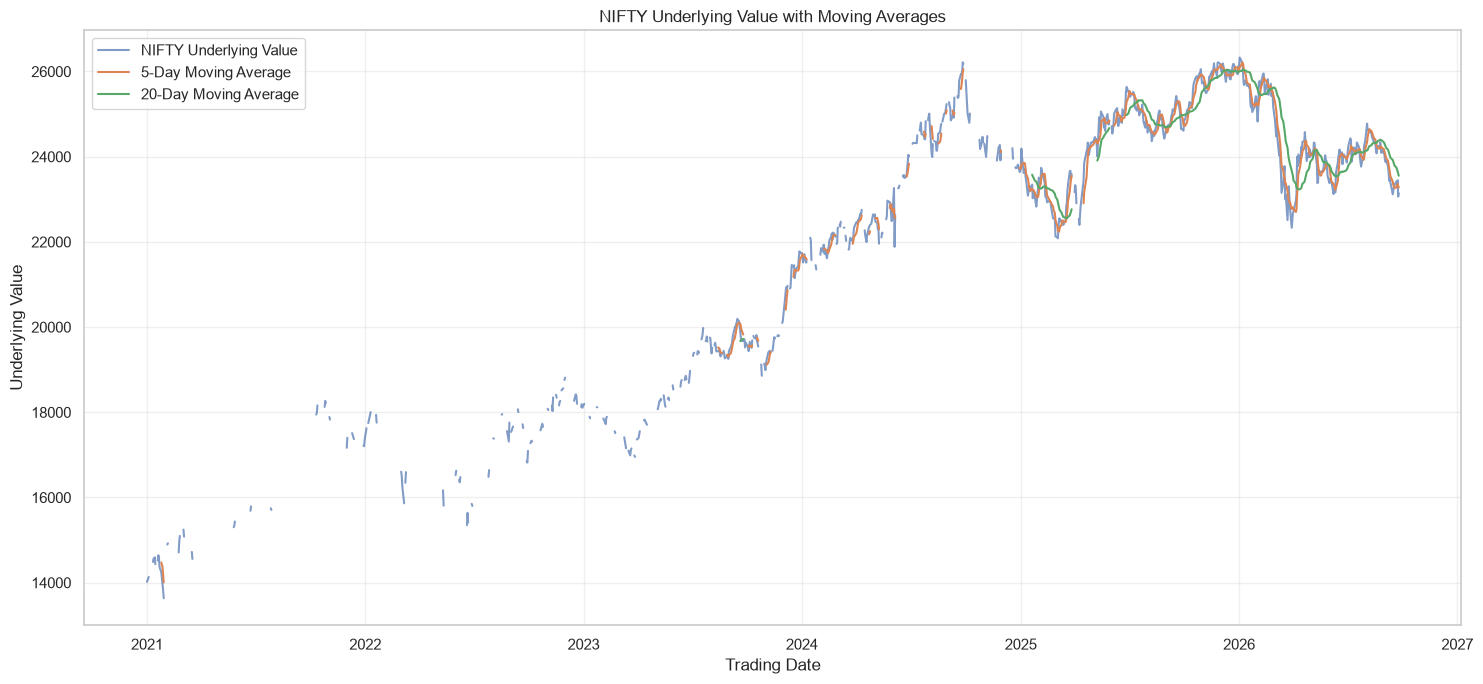

In [19]:
plt.figure(figsize=(15, 7))

plt.plot(
    market_daily["Date"],
    market_daily["Underlying_Value"],
    label="NIFTY Underlying Value",
    alpha=0.7
)

plt.plot(
    market_daily["Date"],
    market_daily["NIFTY_MA_5"],
    label="5-Day Moving Average"
)

plt.plot(
    market_daily["Date"],
    market_daily["NIFTY_MA_20"],
    label="20-Day Moving Average"
)

plt.title("NIFTY Underlying Value with Moving Averages")
plt.xlabel("Trading Date")
plt.ylabel("Underlying Value")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
trend_features = [
    "NIFTY_Return",
    "NIFTY_Return_Lag_1",
    "NIFTY_Return_Lag_2",
    "NIFTY_Return_Lag_3",
    "NIFTY_Return_Lag_5",
    "NIFTY_Return_Lag_10",
    "NIFTY_Momentum_3D",
    "NIFTY_Momentum_5D",
    "NIFTY_Momentum_10D",
    "NIFTY_MA_Deviation_5",
    "NIFTY_MA_Deviation_10",
    "NIFTY_MA_Deviation_20"
]

display(
    market_daily[trend_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
NIFTY_Return,775.0000,0.0320,0.8320,-5.9294,-0.3983,0.0391,0.5055,3.8183
NIFTY_Return_Lag_1,774.0000,0.0317,0.8325,-5.9294,-0.3986,0.0369,0.5057,3.8183
NIFTY_Return_Lag_2,773.0000,0.0338,0.8309,-5.9294,-0.3975,0.0391,0.5060,3.8183
NIFTY_Return_Lag_3,772.0000,0.0332,0.8313,-5.9294,-0.3979,0.0369,0.5063,3.8183
NIFTY_Return_Lag_5,770.0000,0.0334,0.8322,-5.9294,-0.3986,0.0369,0.5070,3.8183
NIFTY_Return_Lag_10,765.0000,0.0343,0.8334,-5.9294,-0.3990,0.0346,0.5088,3.8183
NIFTY_Momentum_3D,772.0000,0.0549,1.4396,-5.3207,-0.8087,0.0711,0.9872,6.0090
NIFTY_Momentum_5D,798.0000,0.1594,1.8643,-6.5506,-0.9414,0.0886,1.3061,9.4587
NIFTY_Momentum_10D,773.0000,0.2722,2.4770,-9.1991,-1.3842,0.3067,2.0127,8.6135
NIFTY_MA_Deviation_5,556.0000,0.0316,0.8868,-3.0565,-0.4822,0.0276,0.5897,3.9010


## 5. Feature Engineering: Volatility and Volume

This section focuses on identifying changes in market volatility and
trading activity.

The following features will be created:

1. Rolling volatility over 5, 10, and 20 trading sessions.
2. Average absolute returns over different periods.
3. Daily changes in Futures, CE, and PE trading volume.
4. Rolling average trading volume.
5. Relative volume compared with recent trading activity.
6. Volume-based market activity indicators.

Rolling volatility will be calculated using the standard deviation of
historical daily returns.

Volume features will help identify unusually active trading sessions.

All rolling indicators will use historical observations up to and
including the current trading session.

In [21]:
# Rolling volatility of NIFTY returns
for window in [5, 10, 20]:

    market_daily[f"NIFTY_Volatility_{window}D"] = (
        market_daily["NIFTY_Return"]
        .rolling(window=window, min_periods=window)
        .std()
    )

display(
    market_daily[
        ["Date", "NIFTY_Return",
         "NIFTY_Volatility_5D",
         "NIFTY_Volatility_10D",
         "NIFTY_Volatility_20D"]
    ].tail(15)
)

,Date,NIFTY_Return,NIFTY_Volatility_5D,NIFTY_Volatility_10D,NIFTY_Volatility_20D
1406,2026-09-04,0.1016,0.2667,0.3668,0.3429
1407,2026-09-07,-0.4961,0.2855,0.3829,0.3487
1408,2026-09-08,-0.6058,0.3078,0.3244,0.3567
1409,2026-09-09,-0.8614,0.3769,0.3664,0.3883
1410,2026-09-10,0.1976,0.4611,0.3958,0.3988
1411,2026-09-11,-0.3395,0.3947,0.3330,0.3998
1412,2026-09-15,-1.1945,0.5287,0.4326,0.4571
1413,2026-09-16,0.4282,0.6856,0.5010,0.4749
1414,2026-09-17,0.2283,0.6566,0.5245,0.4832
1415,2026-09-18,0.3257,0.6751,0.5575,0.4603


In [22]:
# Absolute daily returns
market_daily["NIFTY_Absolute_Return"] = (
    market_daily["NIFTY_Return"].abs()
)

# Rolling average absolute returns
for window in [5, 10, 20]:

    market_daily[f"NIFTY_Avg_Abs_Return_{window}D"] = (
        market_daily["NIFTY_Absolute_Return"]
        .rolling(window=window, min_periods=window)
        .mean()
    )

display(
    market_daily[
        ["Date", "NIFTY_Absolute_Return",
         "NIFTY_Avg_Abs_Return_5D",
         "NIFTY_Avg_Abs_Return_10D",
         "NIFTY_Avg_Abs_Return_20D"]
    ].tail(15)
)

,Date,NIFTY_Absolute_Return,NIFTY_Avg_Abs_Return_5D,NIFTY_Avg_Abs_Return_10D,NIFTY_Avg_Abs_Return_20D
1406,2026-09-04,0.1016,0.2714,0.3325,0.3087
1407,2026-09-07,0.4961,0.2918,0.3686,0.3308
1408,2026-09-08,0.6058,0.3925,0.3815,0.3383
1409,2026-09-09,0.8614,0.4473,0.4155,0.3741
1410,2026-09-10,0.1976,0.4525,0.3870,0.3757
1411,2026-09-11,0.3395,0.5001,0.3857,0.3866
1412,2026-09-15,1.1945,0.6398,0.4658,0.4302
1413,2026-09-16,0.4282,0.6043,0.4984,0.4243
1414,2026-09-17,0.2283,0.4776,0.4624,0.4199
1415,2026-09-18,0.3257,0.5032,0.4779,0.4043


In [23]:
volume_columns = [
    "Futures_Volume",
    "CE_Volume",
    "PE_Volume"
]

for column in volume_columns:

    prefix = column.replace("_Volume", "")

    # Daily absolute volume change
    market_daily[f"{prefix}_Volume_Change"] = (
        market_daily[column].diff()
    )

    # Daily percentage volume change
    market_daily[f"{prefix}_Volume_Pct_Change"] = (
        market_daily[column]
        .pct_change(fill_method=None)
        .replace([np.inf, -np.inf], np.nan)
    )

display(
    market_daily[
        ["Date",
         "Futures_Volume_Change",
         "Futures_Volume_Pct_Change",
         "CE_Volume_Change",
         "CE_Volume_Pct_Change",
         "PE_Volume_Change",
         "PE_Volume_Pct_Change"]
    ].tail(15)
)

,Date,Futures_Volume_Change,Futures_Volume_Pct_Change,CE_Volume_Change,CE_Volume_Pct_Change,PE_Volume_Change,PE_Volume_Pct_Change
1406,2026-09-04,"-11,167.0000",-0.2618,"17,364,624.0000",0.6474,"19,183,139.0000",0.7103
1407,2026-09-07,"11,489.0000",0.3650,"16,952,672.0000",0.3836,"15,815,499.0000",0.3424
1408,2026-09-08,388.0000,0.0090,"82,597,449.0000",1.3509,"75,755,638.0000",1.2217
1409,2026-09-09,"22,618.0000",0.5217,"-112,122,053.0000",-0.7800,"-109,934,291.0000",-0.7980
1410,2026-09-10,"-30,060.0000",-0.4556,"-4,523,834.0000",-0.1431,"-3,557,763.0000",-0.1278
1411,2026-09-11,"26,372.0000",0.7343,"44,730,715.0000",1.6511,"31,578,440.0000",1.3011
1412,2026-09-15,"8,507.0000",0.1366,"88,875,998.0000",1.2374,"99,558,529.0000",1.7826
1413,2026-09-16,"-30,319.0000",-0.4283,"-134,940,343.0000",-0.8397,"-129,979,478.0000",-0.8364
1414,2026-09-17,"-1,345.0000",-0.0332,"5,367,290.0000",0.2084,"3,921,544.0000",0.1542
1415,2026-09-18,"-4,659.0000",-0.1191,"10,816,240.0000",0.3475,"12,252,644.0000",0.4175


In [24]:
for column in volume_columns:

    prefix = column.replace("_Volume", "")

    for window in [5, 10, 20]:

        market_daily[f"{prefix}_Volume_MA_{window}D"] = (
            market_daily[column]
            .rolling(window=window, min_periods=window)
            .mean()
        )

display(
    market_daily[
        ["Date",
         "Futures_Volume",
         "Futures_Volume_MA_5D",
         "Futures_Volume_MA_10D",
         "Futures_Volume_MA_20D"]
    ].tail(15)
)

,Date,Futures_Volume,Futures_Volume_MA_5D,Futures_Volume_MA_10D,Futures_Volume_MA_20D
1406,2026-09-04,"31,481.0000","50,397.8000","68,073.1000","58,097.4500"
1407,2026-09-07,"42,970.0000","48,768.2000","58,983.7000","59,193.1500"
1408,2026-09-08,"43,358.0000","44,470.0000","46,803.6000","59,872.7000"
1409,2026-09-09,"65,976.0000","45,286.6000","48,790.6000","60,386.0500"
1410,2026-09-10,"35,916.0000","43,940.2000","47,908.4000","60,879.9500"
1411,2026-09-11,"62,288.0000","50,101.6000","50,249.7000","62,417.1000"
1412,2026-09-15,"70,795.0000","55,666.6000","52,217.4000","63,816.0000"
1413,2026-09-16,"40,476.0000","55,090.2000","49,780.1000","63,578.4500"
1414,2026-09-17,"39,131.0000","49,721.2000","47,503.9000","62,661.5500"
1415,2026-09-18,"34,472.0000","49,432.4000","46,686.3000","59,235.1000"


In [25]:
for column in volume_columns:

    prefix = column.replace("_Volume", "")

    for window in [5, 10, 20]:

        ma_column = f"{prefix}_Volume_MA_{window}D"

        relative_column = (
            f"{prefix}_Relative_Volume_{window}D"
        )

        market_daily[relative_column] = (
            market_daily[column] /
            market_daily[ma_column].replace(0, np.nan)
        )

display(
    market_daily[
        ["Date",
         "Futures_Relative_Volume_5D",
         "CE_Relative_Volume_5D",
         "PE_Relative_Volume_5D"]
    ].tail(15)
)

,Date,Futures_Relative_Volume_5D,CE_Relative_Volume_5D,PE_Relative_Volume_5D
1406,2026-09-04,0.6247,0.6362,0.6429
1407,2026-09-07,0.8811,0.8919,0.8796
1408,2026-09-08,0.9750,2.3815,2.3175
1409,2026-09-09,1.4569,0.5141,0.4626
1410,2026-09-10,0.8174,0.4401,0.4071
1411,2026-09-11,1.2432,1.0707,0.9075
1412,2026-09-15,1.2718,1.8472,1.9372
1413,2026-09-16,0.7347,0.4063,0.4403
1414,2026-09-17,0.7870,0.4917,0.5055
1415,2026-09-18,0.6974,0.6329,0.6762


In [26]:
for segment in ["Futures", "CE", "PE"]:

    relative_column = f"{segment}_Relative_Volume_20D"

    market_daily[f"{segment}_High_Volume"] = (
        market_daily[relative_column] > 1.5
    ).astype("float")

    # Preserve missing observations as missing
    market_daily.loc[
        market_daily[relative_column].isna(),
        f"{segment}_High_Volume"
    ] = np.nan

display(
    market_daily[
        ["Date",
         "Futures_High_Volume",
         "CE_High_Volume",
         "PE_High_Volume"]
    ].tail(15)
)

,Date,Futures_High_Volume,CE_High_Volume,PE_High_Volume
1406,2026-09-04,0.0000,0.0000,0.0000
1407,2026-09-07,0.0000,0.0000,0.0000
1408,2026-09-08,0.0000,1.0000,1.0000
1409,2026-09-09,0.0000,0.0000,0.0000
1410,2026-09-10,0.0000,0.0000,0.0000
1411,2026-09-11,0.0000,0.0000,0.0000
1412,2026-09-15,0.0000,1.0000,1.0000
1413,2026-09-16,0.0000,0.0000,0.0000
1414,2026-09-17,0.0000,0.0000,0.0000
1415,2026-09-18,0.0000,0.0000,0.0000


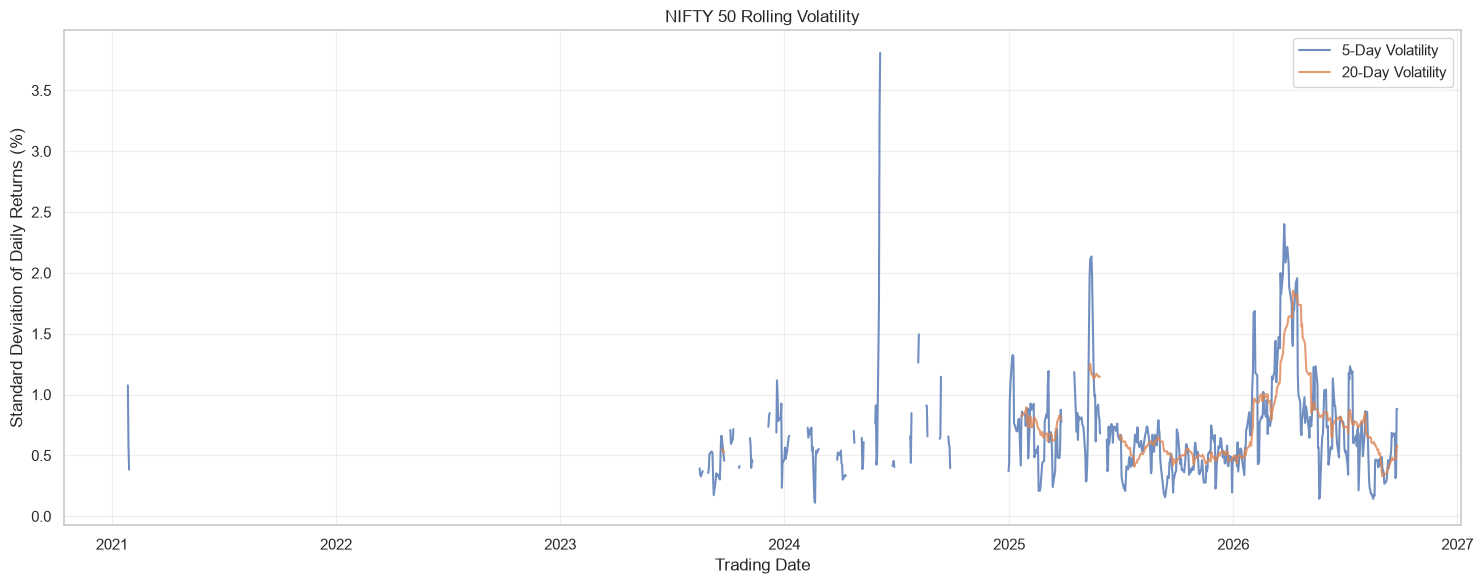

In [27]:
plt.figure(figsize=(15, 6))

plt.plot(
    market_daily["Date"],
    market_daily["NIFTY_Volatility_5D"],
    label="5-Day Volatility",
    alpha=0.8
)

plt.plot(
    market_daily["Date"],
    market_daily["NIFTY_Volatility_20D"],
    label="20-Day Volatility",
    alpha=0.8
)

plt.title("NIFTY 50 Rolling Volatility")
plt.xlabel("Trading Date")
plt.ylabel("Standard Deviation of Daily Returns (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

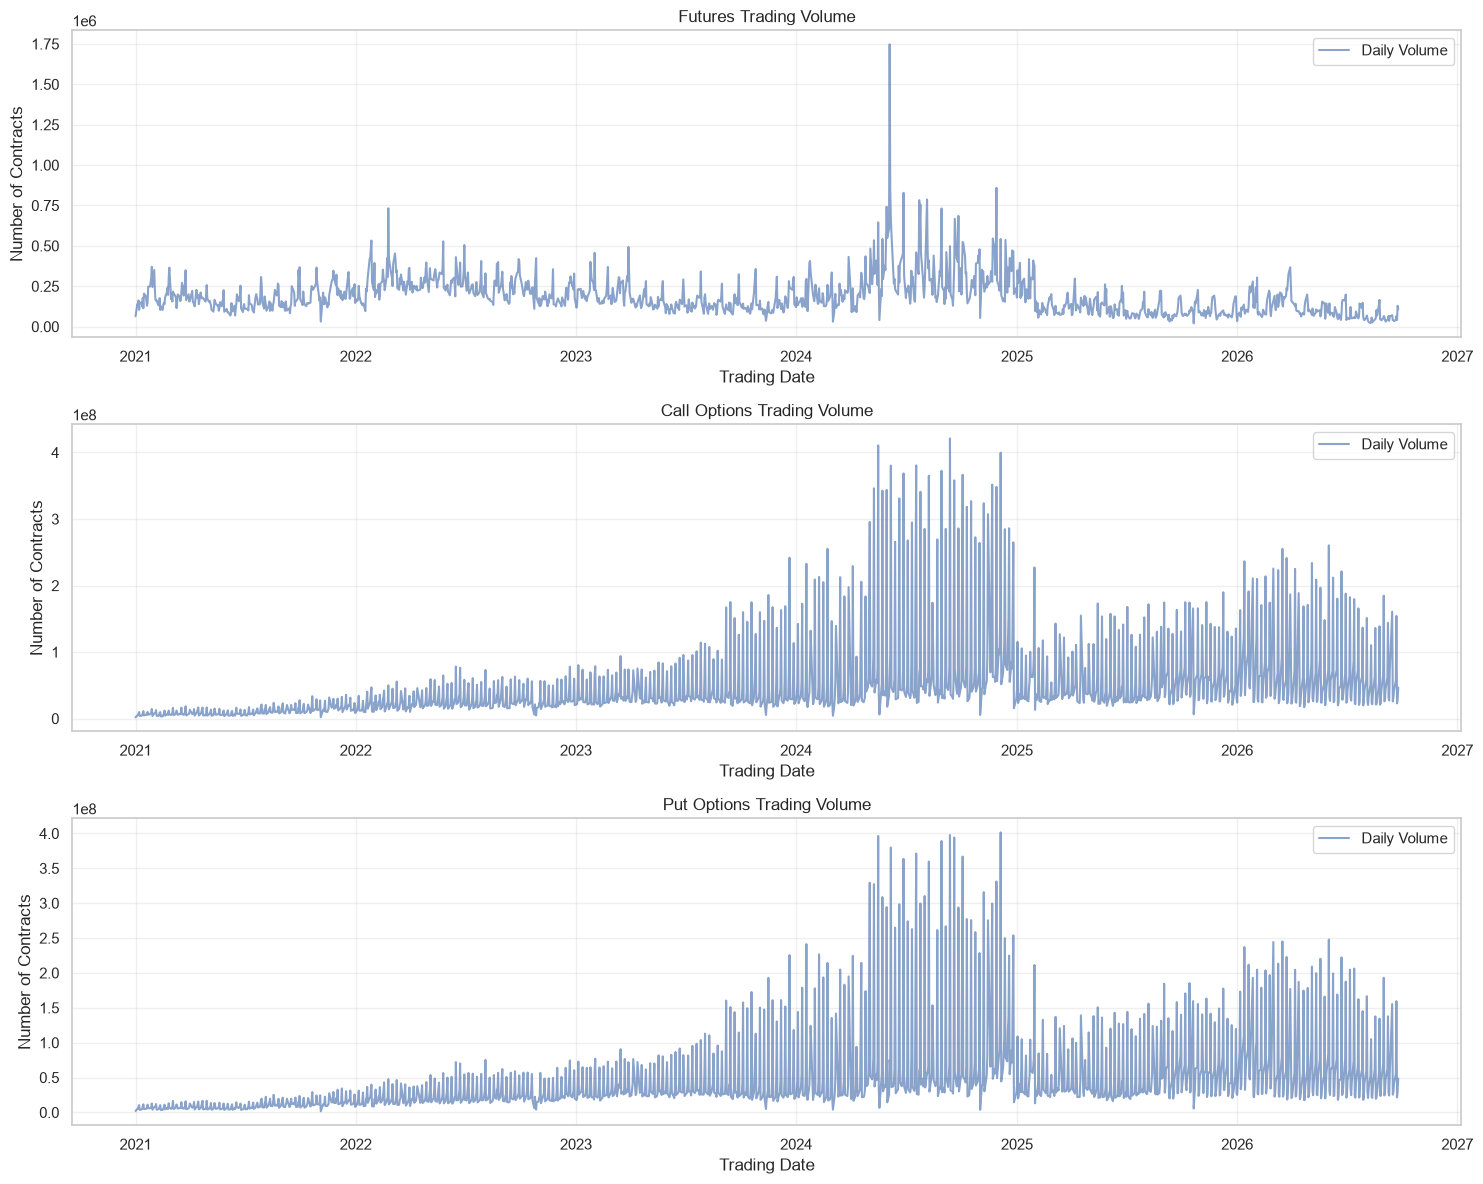

In [28]:
fig, axes = plt.subplots(3, 1, figsize=(15, 12))

segments = [
    ("Futures_Volume", "Futures Trading Volume"),
    ("CE_Volume", "Call Options Trading Volume"),
    ("PE_Volume", "Put Options Trading Volume")
]

for ax, (column, title) in zip(axes, segments):

    ax.plot(
        market_daily["Date"],
        market_daily[column],
        alpha=0.65,
        label="Daily Volume"
    )

    ax.set_title(title)
    ax.set_xlabel("Trading Date")
    ax.set_ylabel("Number of Contracts")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [29]:
volatility_volume_features = [
    "NIFTY_Volatility_5D",
    "NIFTY_Volatility_10D",
    "NIFTY_Volatility_20D",
    "NIFTY_Avg_Abs_Return_5D",
    "NIFTY_Avg_Abs_Return_10D",
    "NIFTY_Avg_Abs_Return_20D",
    "Futures_Volume_Pct_Change",
    "CE_Volume_Pct_Change",
    "PE_Volume_Pct_Change",
    "Futures_Relative_Volume_20D",
    "CE_Relative_Volume_20D",
    "PE_Relative_Volume_20D"
]

display(
    market_daily[volatility_volume_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
NIFTY_Volatility_5D,526.0000,0.6889,0.4186,0.1106,0.4297,0.6042,0.8073,3.8076
NIFTY_Volatility_10D,438.0000,0.7221,0.3543,0.1966,0.4980,0.6330,0.8383,2.6108
NIFTY_Volatility_20D,373.0000,0.7388,0.3100,0.3279,0.5087,0.6499,0.8467,1.8534
NIFTY_Avg_Abs_Return_5D,526.0000,0.5864,0.3268,0.1097,0.3917,0.5133,0.6475,2.7369
NIFTY_Avg_Abs_Return_10D,438.0000,0.5853,0.2782,0.2161,0.4144,0.5103,0.6489,1.7613
NIFTY_Avg_Abs_Return_20D,373.0000,0.5854,0.2599,0.2832,0.4188,0.5006,0.6553,1.5696
Futures_Volume_Pct_Change,"1,420.0000",0.0852,0.5130,-0.8883,-0.1899,0.0058,0.2536,6.6686
CE_Volume_Pct_Change,"1,420.0000",0.3753,1.0362,-0.9797,-0.1269,0.2206,0.7061,9.0759
PE_Volume_Pct_Change,"1,420.0000",0.3978,1.0931,-0.9836,-0.1265,0.2414,0.7289,9.3412
Futures_Relative_Volume_20D,"1,402.0000",0.9973,0.4071,0.1310,0.7287,0.8991,1.1819,3.7585


## 6. Feature Engineering: Open Interest and Options Market Features

Open Interest (OI) represents the number of outstanding derivative
contracts that have not been settled or closed.

In this section, Futures, Call Options (CE), and Put Options (PE)
Open Interest data will be transformed into machine learning features.

The following indicators will be constructed:

1. Daily Open Interest changes.
2. Percentage changes in Open Interest.
3. Put-Call Ratio (PCR) based on aggregate Open Interest.
4. Daily changes in PCR.
5. Rolling PCR averages.
6. Call-to-Put trading volume ratio.
7. Relative changes in CE and PE Open Interest.
8. Derivatives market activity indicators.

PCR will be calculated as aggregate Put Option Open Interest divided
by aggregate Call Option Open Interest.

These indicators will be treated as descriptive market features,
not definitive measures of bullish or bearish sentiment.

All features will use information available up to the current
trading session.

In [30]:
# Calculate daily absolute and percentage changes in OI

oi_columns = [
    "Futures_OI",
    "CE_OI",
    "PE_OI"
]

for column in oi_columns:

    prefix = column.replace("_OI", "")

    # Absolute daily change in aggregate OI
    market_daily[f"{prefix}_OI_Daily_Change"] = (
        market_daily[column].diff()
    )

    # Percentage daily change in aggregate OI
    market_daily[f"{prefix}_OI_Pct_Change"] = (
        market_daily[column]
        .pct_change(fill_method=None)
        .replace([np.inf, -np.inf], np.nan)
    )

display(
    market_daily[
        ["Date",
         "Futures_OI_Daily_Change",
         "CE_OI_Daily_Change",
         "PE_OI_Daily_Change",
         "Futures_OI_Pct_Change",
         "CE_OI_Pct_Change",
         "PE_OI_Pct_Change"]
    ].tail(15)
)

,Date,Futures_OI_Daily_Change,CE_OI_Daily_Change,PE_OI_Daily_Change,Futures_OI_Pct_Change,CE_OI_Pct_Change,PE_OI_Pct_Change
1406,2026-09-04,"-117,975.0000","-3,406,765.0000","36,939,145.0000",-0.0062,-0.0107,0.1460
1407,2026-09-07,"944,710.0000","110,361,290.0000","4,323,535.0000",0.0496,0.3508,0.0149
1408,2026-09-08,"654,095.0000","33,281,040.0000","35,236,265.0000",0.0327,0.0783,0.1198
1409,2026-09-09,"934,635.0000","-165,557,675.0000","-109,354,915.0000",0.0452,-0.3613,-0.3319
1410,2026-09-10,"306,670.0000","36,511,015.0000","33,616,650.0000",0.0142,0.1247,0.1527
1411,2026-09-11,"-14,560.0000","-718,155.0000","76,851,440.0000",-0.0007,-0.0022,0.3029
1412,2026-09-15,"279,890.0000","152,493,685.0000","-6,540,180.0000",0.0128,0.4642,-0.0198
1413,2026-09-16,"-35,360.0000","-232,335,405.0000","-84,965,830.0000",-0.0016,-0.4830,-0.2622
1414,2026-09-17,"107,250.0000","34,512,580.0000","40,573,705.0000",0.0048,0.1388,0.1697
1415,2026-09-18,"154,830.0000","20,672,995.0000","43,150,135.0000",0.0070,0.0730,0.1543


In [31]:
# Calculate OI-based Put-Call Ratio

market_daily["PCR_OI"] = (
    market_daily["PE_OI"] /
    market_daily["CE_OI"].replace(0, np.nan)
)

market_daily["PCR_OI"] = (
    market_daily["PCR_OI"]
    .replace([np.inf, -np.inf], np.nan)
)

display(
    market_daily[
        ["Date", "CE_OI", "PE_OI", "PCR_OI"]
    ].tail(15)
)

,Date,CE_OI,PE_OI,PCR_OI
1406,2026-09-04,"314,627,780.0000","289,872,250.0000",0.9213
1407,2026-09-07,"424,989,070.0000","294,195,785.0000",0.6922
1408,2026-09-08,"458,270,110.0000","329,432,050.0000",0.7189
1409,2026-09-09,"292,712,435.0000","220,077,135.0000",0.7519
1410,2026-09-10,"329,223,450.0000","253,693,785.0000",0.7706
1411,2026-09-11,"328,505,295.0000","330,545,225.0000",1.0062
1412,2026-09-15,"480,998,980.0000","324,005,045.0000",0.6736
1413,2026-09-16,"248,663,575.0000","239,039,215.0000",0.9613
1414,2026-09-17,"283,176,155.0000","279,612,920.0000",0.9874
1415,2026-09-18,"303,849,150.0000","322,763,055.0000",1.0622


In [32]:
# Absolute daily change in PCR
market_daily["PCR_OI_Change"] = (
    market_daily["PCR_OI"].diff()
)

# Percentage daily change in PCR
market_daily["PCR_OI_Pct_Change"] = (
    market_daily["PCR_OI"]
    .pct_change(fill_method=None)
    .replace([np.inf, -np.inf], np.nan)
)

display(
    market_daily[
        ["Date", "PCR_OI",
         "PCR_OI_Change",
         "PCR_OI_Pct_Change"]
    ].tail(15)
)

,Date,PCR_OI,PCR_OI_Change,PCR_OI_Pct_Change
1406,2026-09-04,0.9213,0.1260,0.1585
1407,2026-09-07,0.6922,-0.2291,-0.2486
1408,2026-09-08,0.7189,0.0266,0.0385
1409,2026-09-09,0.7519,0.0330,0.0459
1410,2026-09-10,0.7706,0.0187,0.0249
1411,2026-09-11,1.0062,0.2356,0.3058
1412,2026-09-15,0.6736,-0.3326,-0.3305
1413,2026-09-16,0.9613,0.2877,0.4271
1414,2026-09-17,0.9874,0.0261,0.0272
1415,2026-09-18,1.0622,0.0748,0.0758


In [33]:
# Rolling averages of PCR
for window in [5, 10, 20]:

    market_daily[f"PCR_OI_MA_{window}D"] = (
        market_daily["PCR_OI"]
        .rolling(window=window, min_periods=window)
        .mean()
    )

display(
    market_daily[
        ["Date", "PCR_OI",
         "PCR_OI_MA_5D",
         "PCR_OI_MA_10D",
         "PCR_OI_MA_20D"]
    ].tail(15)
)

,Date,PCR_OI,PCR_OI_MA_5D,PCR_OI_MA_10D,PCR_OI_MA_20D
1406,2026-09-04,0.9213,0.8743,0.8895,0.9193
1407,2026-09-07,0.6922,0.8315,0.8759,0.9045
1408,2026-09-08,0.7189,0.8000,0.8350,0.8968
1409,2026-09-09,0.7519,0.7759,0.8196,0.8886
1410,2026-09-10,0.7706,0.7710,0.8194,0.8811
1411,2026-09-11,1.0062,0.7879,0.8311,0.8823
1412,2026-09-15,0.6736,0.7842,0.8078,0.8664
1413,2026-09-16,0.9613,0.8327,0.8164,0.8759
1414,2026-09-17,0.9874,0.8798,0.8279,0.8847
1415,2026-09-18,1.0622,0.9382,0.8546,0.8817


In [34]:
market_daily["CE_PE_Volume_Ratio"] = (
    market_daily["CE_Volume"] /
    market_daily["PE_Volume"].replace(0, np.nan)
)

market_daily["CE_PE_Volume_Ratio"] = (
    market_daily["CE_PE_Volume_Ratio"]
    .replace([np.inf, -np.inf], np.nan)
)

display(
    market_daily[
        ["Date", "CE_Volume",
         "PE_Volume", "CE_PE_Volume_Ratio"]
    ].tail(15)
)

,Date,CE_Volume,PE_Volume,CE_PE_Volume_Ratio
1406,2026-09-04,"44,187,907.0000","46,191,164.0000",0.9566
1407,2026-09-07,"61,140,579.0000","62,006,663.0000",0.9860
1408,2026-09-08,"143,738,028.0000","137,762,301.0000",1.0434
1409,2026-09-09,"31,615,975.0000","27,828,010.0000",1.1361
1410,2026-09-10,"27,092,141.0000","24,270,247.0000",1.1163
1411,2026-09-11,"71,822,856.0000","55,848,687.0000",1.2860
1412,2026-09-15,"160,698,854.0000","155,407,216.0000",1.0341
1413,2026-09-16,"25,758,511.0000","25,427,738.0000",1.0130
1414,2026-09-17,"31,125,801.0000","29,349,282.0000",1.0605
1415,2026-09-18,"41,942,041.0000","41,601,926.0000",1.0082


In [35]:
# Compare CE and PE OI with their recent moving averages

for segment in ["CE", "PE", "Futures"]:

    oi_column = f"{segment}_OI"

    for window in [5, 10, 20]:

        ma_column = f"{segment}_OI_MA_{window}D"

        market_daily[ma_column] = (
            market_daily[oi_column]
            .rolling(window=window, min_periods=window)
            .mean()
        )

        market_daily[
            f"{segment}_Relative_OI_{window}D"
        ] = (
            market_daily[oi_column] /
            market_daily[ma_column].replace(0, np.nan)
        )

display(
    market_daily[
        ["Date",
         "CE_Relative_OI_5D",
         "PE_Relative_OI_5D",
         "Futures_Relative_OI_5D"]
    ].tail(15)
)

/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/2835354236.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market_daily[
/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/2835354236.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market_daily[ma_column] = (
/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/2835354236.py:17: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Cons

,Date,CE_Relative_OI_5D,PE_Relative_OI_5D,Futures_Relative_OI_5D
1406,2026-09-04,0.9691,1.0209,1.0325
1407,2026-09-07,1.2371,1.0400,1.0547
1408,2026-09-08,1.2958,1.1879,1.0590
1409,2026-09-09,0.8092,0.7936,1.0743
1410,2026-09-10,0.9045,0.9144,1.0609
1411,2026-09-11,0.8957,1.1574,1.0319
1412,2026-09-15,1.2727,1.1113,1.0242
1413,2026-09-16,0.7400,0.8741,1.0089
1414,2026-09-17,0.8475,0.9798,1.0079
1415,2026-09-18,0.9234,1.0788,1.0104


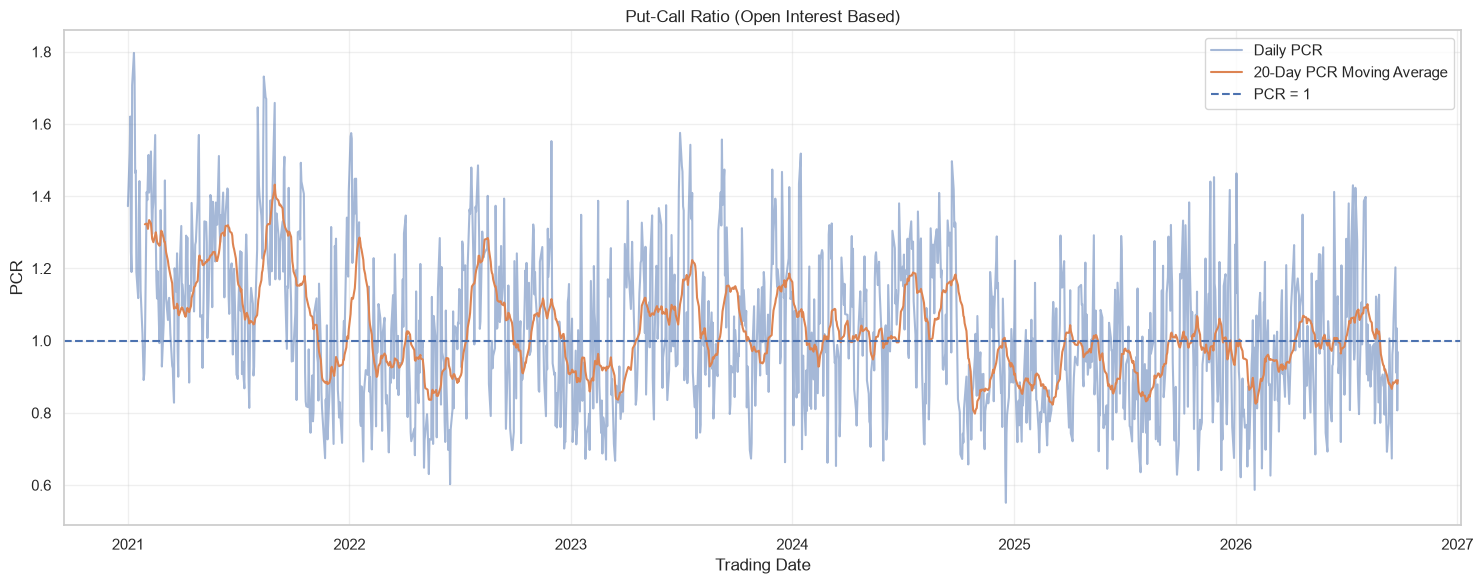

In [36]:
plt.figure(figsize=(15, 6))

plt.plot(
    market_daily["Date"],
    market_daily["PCR_OI"],
    label="Daily PCR",
    alpha=0.5
)

plt.plot(
    market_daily["Date"],
    market_daily["PCR_OI_MA_20D"],
    label="20-Day PCR Moving Average"
)

plt.axhline(
    1,
    linestyle="--",
    label="PCR = 1"
)

plt.title("Put-Call Ratio (Open Interest Based)")
plt.xlabel("Trading Date")
plt.ylabel("PCR")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

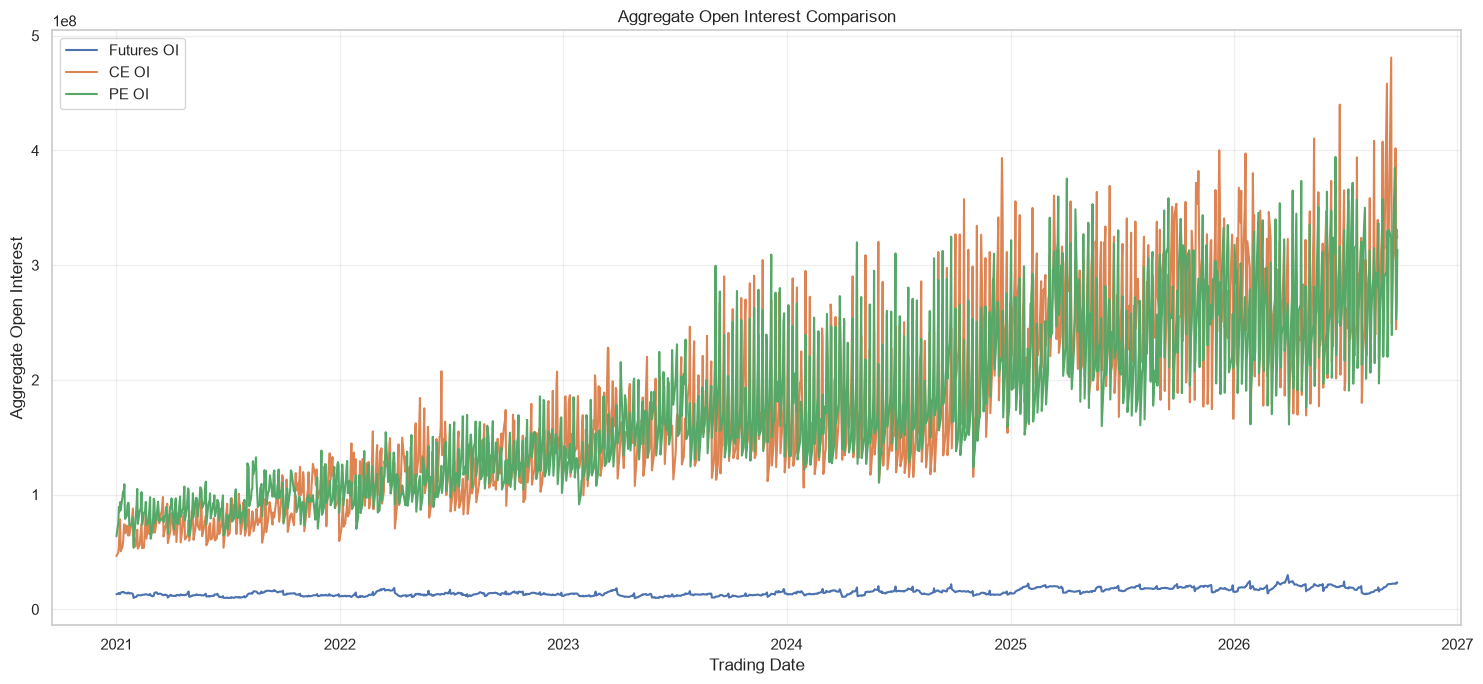

In [37]:
plt.figure(figsize=(15, 7))

plt.plot(
    market_daily["Date"],
    market_daily["Futures_OI"],
    label="Futures OI"
)

plt.plot(
    market_daily["Date"],
    market_daily["CE_OI"],
    label="CE OI"
)

plt.plot(
    market_daily["Date"],
    market_daily["PE_OI"],
    label="PE OI"
)

plt.title("Aggregate Open Interest Comparison")
plt.xlabel("Trading Date")
plt.ylabel("Aggregate Open Interest")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
derivatives_features = [
    "Futures_OI_Pct_Change",
    "CE_OI_Pct_Change",
    "PE_OI_Pct_Change",
    "PCR_OI",
    "PCR_OI_Change",
    "PCR_OI_Pct_Change",
    "PCR_OI_MA_5D",
    "PCR_OI_MA_10D",
    "PCR_OI_MA_20D",
    "CE_PE_Volume_Ratio",
    "CE_Relative_OI_5D",
    "PE_Relative_OI_5D",
    "Futures_Relative_OI_5D"
]

display(
    market_daily[derivatives_features].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Futures_OI_Pct_Change,"1,420.0000",0.0027,0.0641,-0.4002,-0.0149,0.0065,0.0330,0.2127
CE_OI_Pct_Change,"1,420.0000",0.0349,0.2416,-0.6547,-0.0612,0.0800,0.1761,0.7925
PE_OI_Pct_Change,"1,420.0000",0.0272,0.2142,-0.6036,-0.0411,0.0662,0.1554,0.5829
PCR_OI,"1,421.0000",1.0278,0.2148,0.5511,0.8625,1.0013,1.1785,1.7967
PCR_OI_Change,"1,420.0000",-0.0003,0.1793,-0.5763,-0.1188,0.0026,0.1140,0.6279
PCR_OI_Pct_Change,"1,420.0000",0.0157,0.1824,-0.4732,-0.1128,0.0027,0.1223,0.7612
PCR_OI_MA_5D,"1,417.0000",1.0274,0.1650,0.7076,0.9084,1.0115,1.1271,1.6339
PCR_OI_MA_10D,"1,412.0000",1.0266,0.1418,0.7449,0.9209,1.0139,1.1057,1.5120
PCR_OI_MA_20D,"1,402.0000",1.0258,0.1196,0.7979,0.9381,1.0064,1.0907,1.4320
CE_PE_Volume_Ratio,"1,421.0000",1.0692,0.0982,0.8082,1.0032,1.0586,1.1272,1.7296


## 7. Target Variable Creation

The primary objective is to predict the direction of the NIFTY 50
market for the next trading session.

The target variable will be constructed using the next session's
percentage return of the underlying NIFTY value proxy.

Three classes will be defined:

- 1: Up — next-session return greater than +0.10%.
- -1: Down — next-session return less than -0.10%.
- 0: Sideways — next-session return between -0.10% and +0.10%,
  including the boundaries.

The target return will be shifted by one trading session so that
features from the current session are used to predict the next session.

The target variable will not be included among the model input features.

The final observation will have no next-session target and will
therefore be excluded from supervised model training.

In [39]:
# Initial sideways threshold in percentage points
SIDEWAYS_THRESHOLD = 0.10

print(
    f"Sideways threshold: ±{SIDEWAYS_THRESHOLD:.2f}%"
)

Sideways threshold: ±0.10%


In [40]:
# Predict the next row in the observed trading-date panel.
# The target return is valid only if proxy values exist on BOTH date t and date t+1.
# No forward-fill/interpolation is used; missing values produce missing labels.

market_daily["Target_Date"] = market_daily["Date"].shift(-1)
next_proxy_value = market_daily["Underlying_Value"].shift(-1)

market_daily["Next_Session_Return"] = (
    (next_proxy_value / market_daily["Underlying_Value"]) - 1
) * 100

# Explicit validity flag for auditability.
market_daily["Valid_Next_Session_Target"] = (
    market_daily["Underlying_Value"].notna()
    & next_proxy_value.notna()
    & market_daily["Target_Date"].notna()
)

market_daily.loc[
    ~market_daily["Valid_Next_Session_Target"],
    "Next_Session_Return"
] = np.nan

display(
    market_daily[
        ["Date", "Underlying_Value", "Target_Date",
         "Next_Session_Return", "Valid_Next_Session_Target"]
    ].head(15)
)


/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/1023686676.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market_daily["Target_Date"] = market_daily["Date"].shift(-1)
/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/1023686676.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market_daily["Next_Session_Return"] = (
/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/1023686676.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `fr

,Date,Underlying_Value,Target_Date,Next_Session_Return,Valid_Next_Session_Target
0,2021-01-01,"14,018.5000",2021-01-04,0.8161,True
1,2021-01-04,"14,132.9000",2021-01-05,NaN,False
2,2021-01-05,NaN,2021-01-06,NaN,False
3,2021-01-06,NaN,2021-01-07,NaN,False
4,2021-01-07,"14,137.3500",2021-01-08,NaN,False
5,2021-01-08,NaN,2021-01-11,NaN,False
6,2021-01-11,"14,484.7500",2021-01-12,0.5433,True
7,2021-01-12,"14,563.4500",2021-01-13,0.0096,True
8,2021-01-13,"14,564.8500",2021-01-14,0.2111,True
9,2021-01-14,"14,595.6000",2021-01-15,-1.1092,True


In [41]:
# Initialize target as missing.
market_daily["Target_Direction"] = pd.Series(
    pd.NA, index=market_daily.index, dtype="Int8"
)

valid_target = (
    market_daily["Valid_Next_Session_Target"]
    & market_daily["Next_Session_Return"].notna()
)

market_daily.loc[
    valid_target & (market_daily["Next_Session_Return"] > SIDEWAYS_THRESHOLD),
    "Target_Direction"
] = 1

market_daily.loc[
    valid_target & (market_daily["Next_Session_Return"] < -SIDEWAYS_THRESHOLD),
    "Target_Direction"
] = -1

market_daily.loc[
    valid_target & market_daily["Next_Session_Return"].between(
        -SIDEWAYS_THRESHOLD, SIDEWAYS_THRESHOLD, inclusive="both"
    ),
    "Target_Direction"
] = 0

direction_labels = {1: "Up", -1: "Down", 0: "Sideways"}
market_daily["Target_Label"] = market_daily["Target_Direction"].map(direction_labels)

print("Valid target observations:", int(market_daily["Target_Direction"].notna().sum()))
print("Total market dates:", len(market_daily))
print("Target coverage (%):", round(market_daily["Target_Direction"].notna().mean() * 100, 2))
display(
    market_daily[
        ["Date", "Target_Date", "Next_Session_Return",
         "Target_Direction", "Target_Label"]
    ].head(15)
)


Valid target observations: 775
Total market dates: 1421
Target coverage (%): 54.54


/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/2612176196.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market_daily["Target_Direction"] = pd.Series(
/var/folders/ts/5m6b5syd7h79dznvtq88l72h0000gn/T/ipykernel_16095/2612176196.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  market_daily["Target_Label"] = market_daily["Target_Direction"].map(direction_labels)


,Date,Target_Date,Next_Session_Return,Target_Direction,Target_Label
0,2021-01-01,2021-01-04,0.8161,1,Up
1,2021-01-04,2021-01-05,NaN,<NA>,NaN
2,2021-01-05,2021-01-06,NaN,<NA>,NaN
3,2021-01-06,2021-01-07,NaN,<NA>,NaN
4,2021-01-07,2021-01-08,NaN,<NA>,NaN
5,2021-01-08,2021-01-11,NaN,<NA>,NaN
6,2021-01-11,2021-01-12,0.5433,1,Up
7,2021-01-12,2021-01-13,0.0096,0,Sideways
8,2021-01-13,2021-01-14,0.2111,1,Up
9,2021-01-14,2021-01-15,-1.1092,-1,Down


In [42]:
target_counts = (
    market_daily["Target_Label"]
    .value_counts()
    .reindex(["Up", "Down", "Sideways"], fill_value=0)
)

target_percentages = (
    market_daily["Target_Label"]
    .value_counts(normalize=True)
    .reindex(["Up", "Down", "Sideways"], fill_value=0)
    * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary)

print(
    "Valid target observations:",
    market_daily["Target_Direction"].notna().sum()
)

print(
    "Missing target observations:",
    market_daily["Target_Direction"].isna().sum()
)

,Count,Percentage
Target_Label,,
Up,360,46.4516
Down,322,41.5484
Sideways,93,12.0000


Valid target observations: 775
Missing target observations: 646


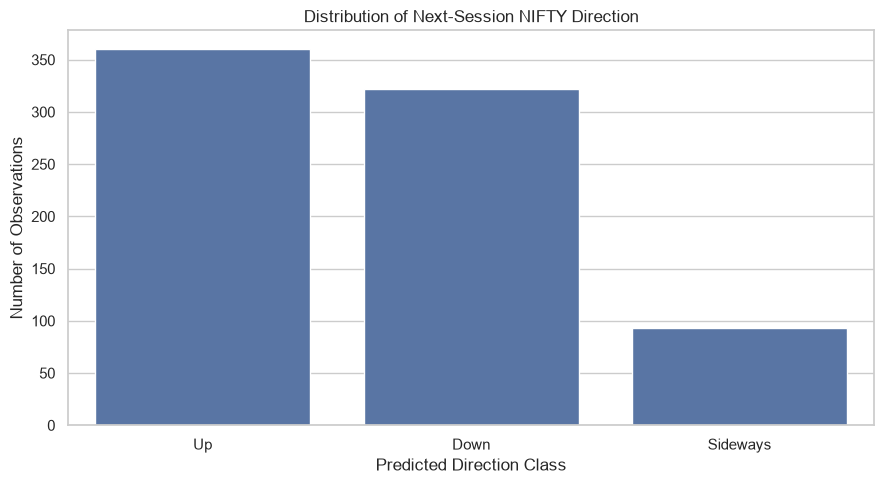

In [43]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=market_daily,
    x="Target_Label",
    order=["Up", "Down", "Sideways"]
)

plt.title("Distribution of Next-Session NIFTY Direction")
plt.xlabel("Predicted Direction Class")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

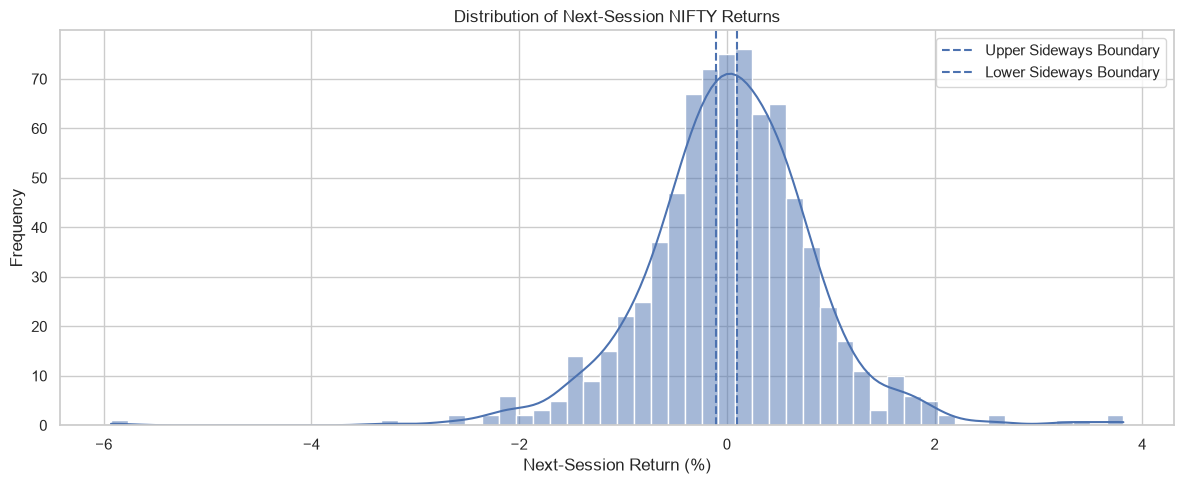

In [44]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=market_daily,
    x="Next_Session_Return",
    bins=60,
    kde=True
)

plt.axvline(
    SIDEWAYS_THRESHOLD,
    linestyle="--",
    label="Upper Sideways Boundary"
)

plt.axvline(
    -SIDEWAYS_THRESHOLD,
    linestyle="--",
    label="Lower Sideways Boundary"
)

plt.title("Distribution of Next-Session NIFTY Returns")
plt.xlabel("Next-Session Return (%)")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()

In [45]:
# Verify that the target date is the next available trading date
expected_target_dates = market_daily["Date"].shift(-1)

date_alignment_check = (
    market_daily["Target_Date"].equals(expected_target_dates)
)

# Verify class mapping
print("Target date alignment:", date_alignment_check)

print("\nTarget class mapping:")
print(direction_labels)

print("\nTarget value counts:")
print(
    market_daily["Target_Direction"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nMissing next-session returns:",
      market_daily["Next_Session_Return"].isna().sum())

print("\nTarget creation completed.")

Target date alignment: True

Target class mapping:
{1: 'Up', -1: 'Down', 0: 'Sideways'}

Target value counts:
Target_Direction
-1      322
0        93
1       360
<NA>    646
Name: count, dtype: Int64

Missing next-session returns: 646

Target creation completed.


## 8. Feature Selection and Missing Value Treatment

This section prepares the engineered market features for machine
learning.

The following steps will be performed:

1. Define the candidate predictor variables.
2. Exclude target-related and future information.
3. Inspect missing values in the candidate features.
4. Remove features with excessive missing observations.
5. Identify constant or near-constant features.
6. Examine correlations between predictor variables.
7. Prepare the feature matrix and target vector.

Missing values will not be replaced with zero automatically.

Imputation and scaling will be fitted using training data only,
after chronological splitting, to prevent data leakage.

The target variable and future-session information will never
be included in the predictor matrix.

In [46]:
# Candidate predictor features

candidate_features = [
    # NIFTY returns and momentum
    "NIFTY_Return",
    "NIFTY_Return_Lag_1",
    "NIFTY_Return_Lag_2",
    "NIFTY_Return_Lag_3",
    "NIFTY_Return_Lag_5",
    "NIFTY_Return_Lag_10",
    "NIFTY_Momentum_3D",
    "NIFTY_Momentum_5D",
    "NIFTY_Momentum_10D",

    # Moving average deviations
    "NIFTY_MA_Deviation_5",
    "NIFTY_MA_Deviation_10",
    "NIFTY_MA_Deviation_20",

    # Volatility
    "NIFTY_Volatility_5D",
    "NIFTY_Volatility_10D",
    "NIFTY_Volatility_20D",
    "NIFTY_Avg_Abs_Return_5D",
    "NIFTY_Avg_Abs_Return_10D",
    "NIFTY_Avg_Abs_Return_20D",

    # Volume activity
    "Futures_Volume_Pct_Change",
    "CE_Volume_Pct_Change",
    "PE_Volume_Pct_Change",
    "Futures_Relative_Volume_5D",
    "Futures_Relative_Volume_10D",
    "Futures_Relative_Volume_20D",
    "CE_Relative_Volume_5D",
    "CE_Relative_Volume_10D",
    "CE_Relative_Volume_20D",
    "PE_Relative_Volume_5D",
    "PE_Relative_Volume_10D",
    "PE_Relative_Volume_20D",

    # High-volume indicators
    "Futures_High_Volume",
    "CE_High_Volume",
    "PE_High_Volume",

    # Open Interest changes
    "Futures_OI_Pct_Change",
    "CE_OI_Pct_Change",
    "PE_OI_Pct_Change",

    # Relative Open Interest
    "Futures_Relative_OI_5D",
    "Futures_Relative_OI_10D",
    "Futures_Relative_OI_20D",
    "CE_Relative_OI_5D",
    "CE_Relative_OI_10D",
    "CE_Relative_OI_20D",
    "PE_Relative_OI_5D",
    "PE_Relative_OI_10D",
    "PE_Relative_OI_20D",

    # Options indicators
    "PCR_OI",
    "PCR_OI_Change",
    "PCR_OI_Pct_Change",
    "PCR_OI_MA_5D",
    "PCR_OI_MA_10D",
    "PCR_OI_MA_20D",
    "CE_PE_Volume_Ratio"
]

# Verify candidate columns
available_features = [
    col for col in candidate_features
    if col in market_daily.columns
]

missing_features = [
    col for col in candidate_features
    if col not in market_daily.columns
]

print("Candidate features requested:", len(candidate_features))
print("Available features:", len(available_features))
print("Missing feature columns:", missing_features)

if missing_features:
    raise ValueError(
        "Some expected engineered features are missing. "
        "Check that Sections 3–7 have been executed correctly."
    )

Candidate features requested: 52
Available features: 52
Missing feature columns: []


In [47]:
# Create a modelling dataset
model_data = market_daily[
    ["Date", "Target_Date", "Target_Direction"] + available_features
].copy()

# Remove rows without a valid target
model_data = model_data.dropna(
    subset=["Target_Direction"]
).reset_index(drop=True)

# Separate predictors and target
X = model_data[available_features].copy()
y = model_data["Target_Direction"].astype(int).copy()

# Ensure predictor values are numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

print("Modelling dataset created.")
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().sort_index())

display(X.head())

Modelling dataset created.
Feature matrix shape: (775, 52)
Target vector shape: (775,)

Target distribution:


Target_Direction
-1    322
 0     93
 1    360
Name: count, dtype: int64

,NIFTY_Return,NIFTY_Return_Lag_1,NIFTY_Return_Lag_2,NIFTY_Return_Lag_3,NIFTY_Return_Lag_5,NIFTY_Return_Lag_10,NIFTY_Momentum_3D,NIFTY_Momentum_5D,NIFTY_Momentum_10D,NIFTY_MA_Deviation_5,NIFTY_MA_Deviation_10,NIFTY_MA_Deviation_20,NIFTY_Volatility_5D,NIFTY_Volatility_10D,NIFTY_Volatility_20D,NIFTY_Avg_Abs_Return_5D,NIFTY_Avg_Abs_Return_10D,NIFTY_Avg_Abs_Return_20D,Futures_Volume_Pct_Change,CE_Volume_Pct_Change,PE_Volume_Pct_Change,Futures_Relative_Volume_5D,Futures_Relative_Volume_10D,Futures_Relative_Volume_20D,CE_Relative_Volume_5D,CE_Relative_Volume_10D,CE_Relative_Volume_20D,PE_Relative_Volume_5D,PE_Relative_Volume_10D,PE_Relative_Volume_20D,Futures_High_Volume,CE_High_Volume,PE_High_Volume,Futures_OI_Pct_Change,CE_OI_Pct_Change,PE_OI_Pct_Change,Futures_Relative_OI_5D,Futures_Relative_OI_10D,Futures_Relative_OI_20D,CE_Relative_OI_5D,CE_Relative_OI_10D,CE_Relative_OI_20D,PE_Relative_OI_5D,PE_Relative_OI_10D,PE_Relative_OI_20D,PCR_OI,PCR_OI_Change,PCR_OI_Pct_Change,PCR_OI_MA_5D,PCR_OI_MA_10D,PCR_OI_MA_20D,CE_PE_Volume_Ratio
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.3725,NaN,NaN,NaN,NaN,NaN,0.9249
1,NaN,NaN,NaN,NaN,0.8161,NaN,NaN,2.4896,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0150,0.0556,0.2558,1.0702,NaN,NaN,0.6856,NaN,NaN,0.7064,NaN,NaN,NaN,NaN,NaN,0.0425,0.0825,0.1392,1.0694,NaN,NaN,0.8918,NaN,NaN,1.0878,NaN,NaN,1.7967,0.0895,0.0524,1.5121,NaN,NaN,0.9441
2,0.5433,NaN,NaN,NaN,NaN,NaN,3.0140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.1694,0.2096,0.0494,0.9036,NaN,NaN,0.8348,NaN,NaN,0.7510,NaN,NaN,NaN,NaN,NaN,0.0059,0.0841,0.0436,1.0615,NaN,NaN,0.9530,NaN,NaN,1.1020,NaN,NaN,1.7297,-0.0670,-0.0373,1.5339,NaN,NaN,1.0882
3,0.0096,0.5433,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4316,0.5254,0.8141,1.2650,NaN,NaN,1.2624,NaN,NaN,1.3456,NaN,NaN,NaN,NaN,NaN,-0.0398,0.1703,-0.0090,1.0029,NaN,NaN,1.1114,NaN,NaN,1.0546,NaN,NaN,1.4648,-0.2649,-0.1531,1.5777,NaN,NaN,0.9150
4,0.2111,0.0096,0.5433,NaN,NaN,NaN,0.7653,3.2414,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.3604,0.4235,0.3546,0.7979,0.8628,NaN,1.7215,1.8106,NaN,1.7595,1.8242,NaN,NaN,NaN,NaN,0.0035,0.0657,0.0705,0.9890,1.0318,NaN,1.2010,1.2226,NaN,1.0934,1.2046,NaN,1.4713,0.0065,0.0044,1.6339,1.5120,NaN,0.9616


In [48]:
# Columns that must never be used as predictors
forbidden_columns = [
    "Target_Date",
    "Next_Session_Return",
    "Target_Direction",
    "Target_Label",
    "Date"
]

leakage_columns = [
    col for col in X.columns
    if col in forbidden_columns
]

print("Forbidden columns present:", leakage_columns)

assert len(leakage_columns) == 0, (
    "Target leakage detected in predictor columns!"
)

assert "Next_Session_Return" not in X.columns
assert "Target_Direction" not in X.columns
assert "Target_Label" not in X.columns
assert "Target_Date" not in X.columns

print("Leakage checks passed.")

Forbidden columns present: []
Leakage checks passed.


In [49]:
missing_summary = pd.DataFrame({
    "Missing_Count": X.isna().sum(),
    "Missing_Percentage": X.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
NIFTY_Avg_Abs_Return_20D,406,52.3871
NIFTY_Volatility_20D,406,52.3871
NIFTY_MA_Deviation_20,402,51.8710
NIFTY_Volatility_10D,345,44.5161
NIFTY_Avg_Abs_Return_10D,345,44.5161
NIFTY_MA_Deviation_10,337,43.4839
NIFTY_Volatility_5D,273,35.2258
NIFTY_Avg_Abs_Return_5D,273,35.2258
NIFTY_MA_Deviation_5,249,32.1290
NIFTY_Return_Lag_10,181,23.3548


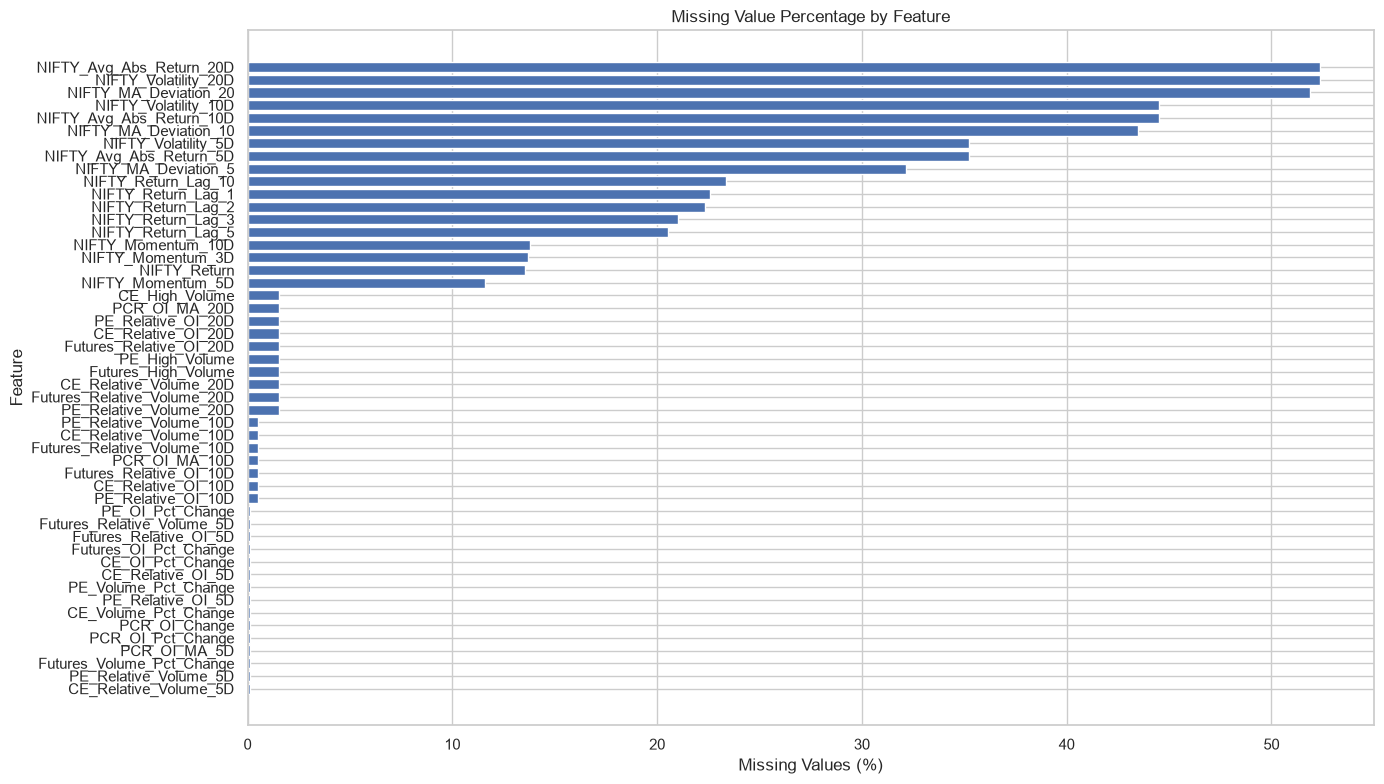

In [50]:
plt.figure(figsize=(14, 8))

missing_plot = (
    missing_summary
    .query("Missing_Percentage > 0")
    .sort_values("Missing_Percentage")
)

if len(missing_plot) > 0:

    plt.barh(
        missing_plot.index,
        missing_plot["Missing_Percentage"]
    )

    plt.xlabel("Missing Values (%)")
    plt.ylabel("Feature")
    plt.title("Missing Value Percentage by Feature")
    plt.tight_layout()
    plt.show()

else:
    print("No missing values found in candidate features.")

In [51]:
# Descriptive missingness report only.
# Do NOT select/drop predictors using the full dataset: that would expose
# validation/test-period information to the feature-selection process.
missing_percentages = X.isna().mean().mul(100).sort_values(ascending=False)

print("Full-period missingness (descriptive only; not used for feature selection):")
display(missing_percentages.to_frame("Missing_Percentage"))
print("Predictor columns retained for the chronological split:", X.shape[1])


Full-period missingness (descriptive only; not used for feature selection):


,Missing_Percentage
NIFTY_Avg_Abs_Return_20D,52.3871
NIFTY_Volatility_20D,52.3871
NIFTY_MA_Deviation_20,51.8710
NIFTY_Volatility_10D,44.5161
NIFTY_Avg_Abs_Return_10D,44.5161
NIFTY_MA_Deviation_10,43.4839
NIFTY_Volatility_5D,35.2258
NIFTY_Avg_Abs_Return_5D,35.2258
NIFTY_MA_Deviation_5,32.1290
NIFTY_Return_Lag_10,23.3548


Predictor columns retained for the chronological split: 52


In [52]:
# Descriptive constant-feature audit only.
# Actual constant-feature removal is performed using TRAINING data only in Section 9.
full_period_constant_features = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

print("Features constant over the full sample (descriptive only):")
print(full_period_constant_features)
print("No columns are removed in this cell.")


Features constant over the full sample (descriptive only):
[]
No columns are removed in this cell.


### 8.1 Feature Redundancy and Correlation

Some engineered features may contain overlapping information.

For example, 5-day, 10-day, and 20-day moving averages can be correlated.
Similarly, multiple volatility and relative-volume indicators may capture
related market behaviour.

Highly correlated features will be identified during the training phase.

Correlation-based feature removal will be decided using training data
only, rather than the complete dataset, to preserve the chronological
evaluation methodology.

No feature will be removed solely because it has a high correlation
with another feature without considering its financial interpretation
and predictive usefulness.

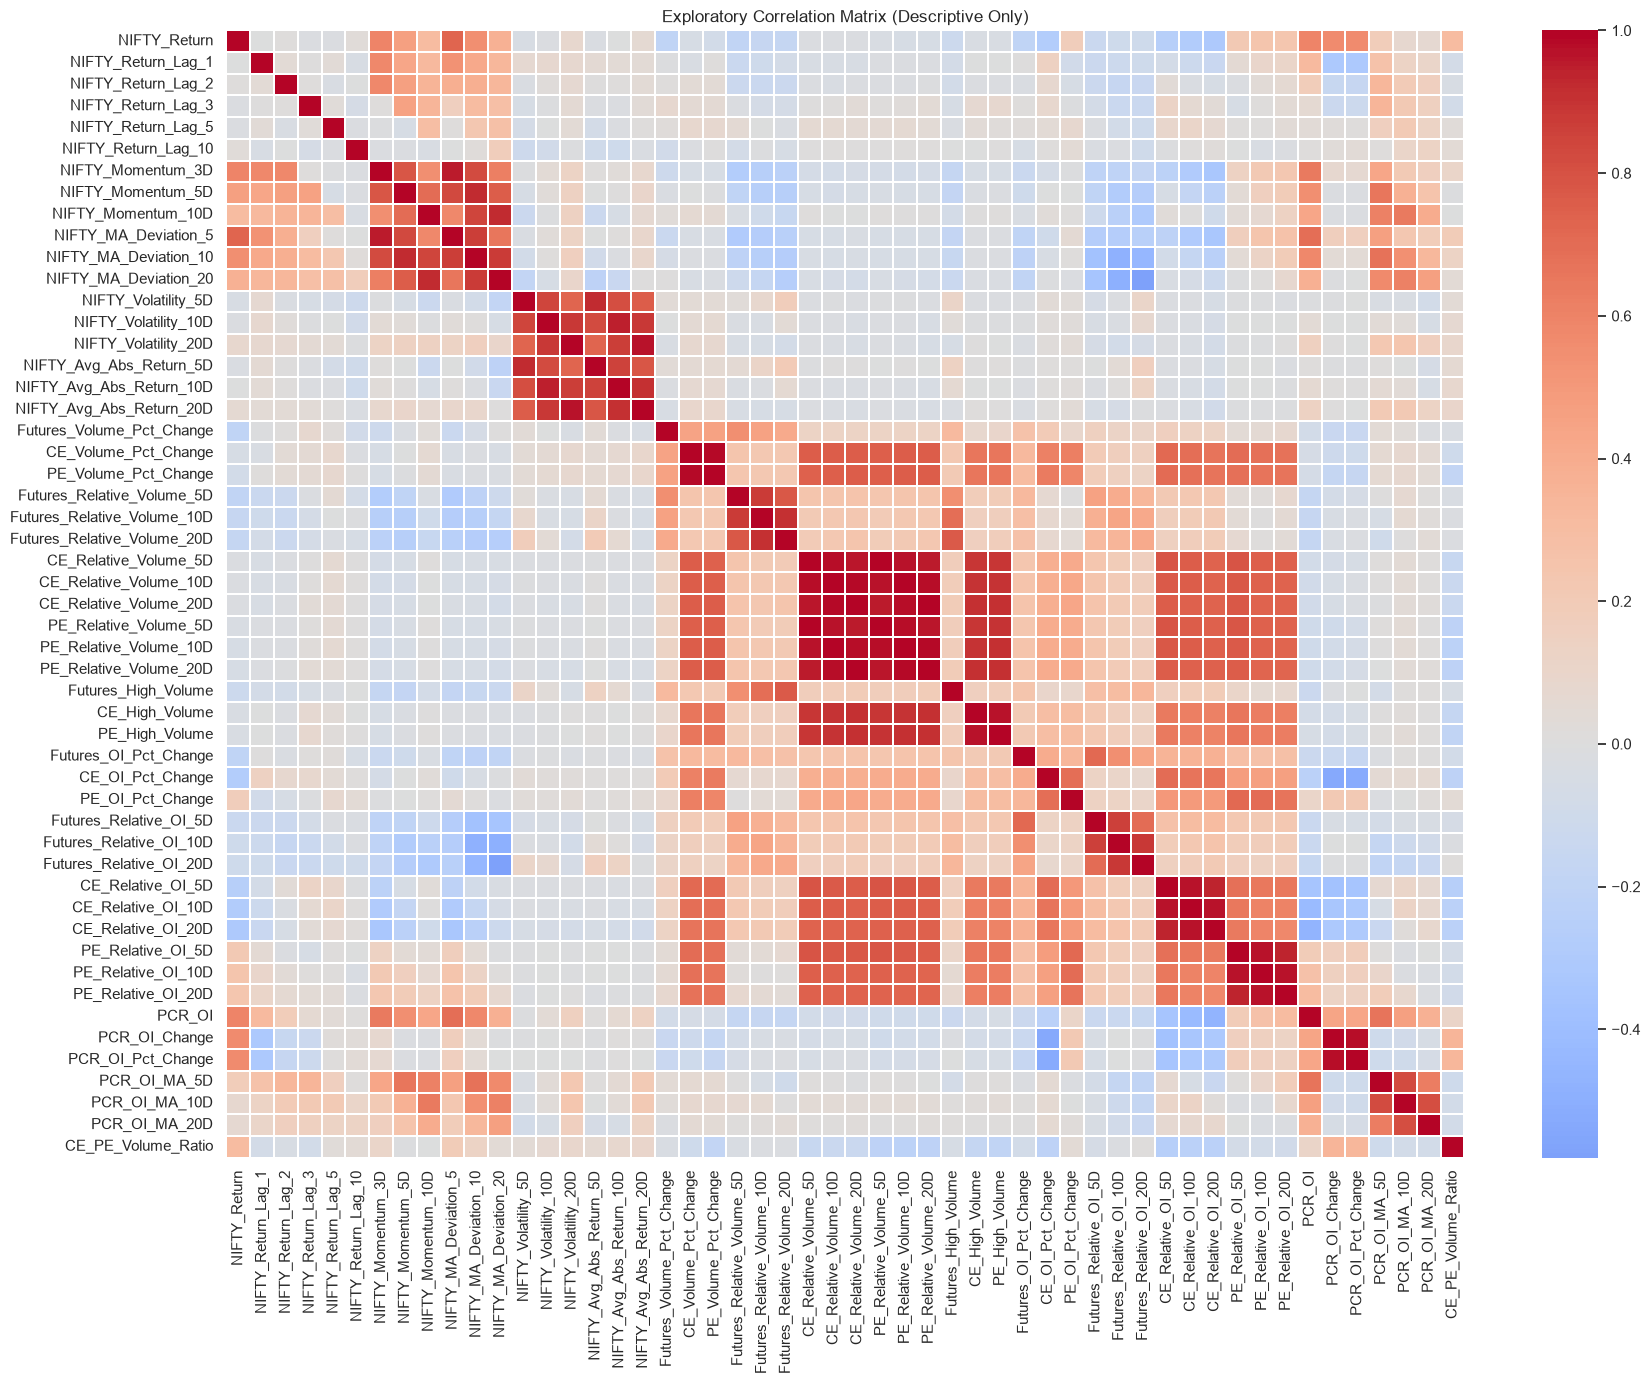

In [53]:
# Exploratory correlation analysis across the available labelled sample.
# This heatmap is descriptive only and is NOT used to select/drop model features.
feature_correlation = X.corr()

plt.figure(figsize=(18, 14))
sns.heatmap(
    feature_correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1,
    xticklabels=True,
    yticklabels=True
)
plt.title("Exploratory Correlation Matrix (Descriptive Only)")
plt.tight_layout()
plt.show()


In [54]:
# Identify highly correlated pairs for documentation only.
correlation_pairs = (
    feature_correlation
    .where(np.triu(np.ones(feature_correlation.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)
correlation_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

high_correlation_pairs = (
    correlation_pairs[
        correlation_pairs["Correlation"].abs() >= 0.95
    ]
    .sort_values("Correlation", key=lambda x: x.abs(), ascending=False)
)

print("Highly correlated pairs (|r| >= 0.95; descriptive only):")
display(high_correlation_pairs)
print("These pairs are not automatically removed. Any selection must be learned from training data only.")


Highly correlated pairs (|r| >= 0.95; descriptive only):


,Feature_1,Feature_2,Correlation
1275,CE_Relative_Volume_5D,PE_Relative_Volume_5D,0.9960
1328,CE_Relative_Volume_10D,PE_Relative_Volume_10D,0.9940
1381,CE_Relative_Volume_20D,PE_Relative_Volume_20D,0.9933
1326,CE_Relative_Volume_10D,CE_Relative_Volume_20D,0.9838
1485,PE_Relative_Volume_10D,PE_Relative_Volume_20D,0.9838
1008,CE_Volume_Pct_Change,PE_Volume_Pct_Change,0.9828
2439,PCR_OI_Change,PCR_OI_Pct_Change,0.9799
1329,CE_Relative_Volume_10D,PE_Relative_Volume_20D,0.9787
1380,CE_Relative_Volume_20D,PE_Relative_Volume_10D,0.9771
1432,PE_Relative_Volume_5D,PE_Relative_Volume_10D,0.9765


These pairs are not automatically removed. Any selection must be learned from training data only.


In [55]:
# Assemble all available candidate predictors with dates and target.
# Feature filtering is deferred until after the chronological split.
ml_dataset = pd.concat(
    [
        model_data[["Date", "Target_Date"]].copy(),
        X.copy(),
        y.rename("Target_Direction")
    ],
    axis=1
).sort_values("Date").reset_index(drop=True)

candidate_feature_columns = X.columns.tolist()

print("Preliminary ML dataset created without full-sample feature filtering.")
print("Shape:", ml_dataset.shape)
print("Date range:", ml_dataset["Date"].min(), "to", ml_dataset["Date"].max())
print("Candidate predictor features:", len(candidate_feature_columns))
display(ml_dataset.head())


Preliminary ML dataset created without full-sample feature filtering.
Shape: (775, 55)
Date range: 2021-01-01 00:00:00 to 2026-09-24 00:00:00
Candidate predictor features: 52


,Date,Target_Date,NIFTY_Return,NIFTY_Return_Lag_1,NIFTY_Return_Lag_2,NIFTY_Return_Lag_3,NIFTY_Return_Lag_5,NIFTY_Return_Lag_10,NIFTY_Momentum_3D,NIFTY_Momentum_5D,NIFTY_Momentum_10D,NIFTY_MA_Deviation_5,NIFTY_MA_Deviation_10,NIFTY_MA_Deviation_20,NIFTY_Volatility_5D,NIFTY_Volatility_10D,NIFTY_Volatility_20D,NIFTY_Avg_Abs_Return_5D,NIFTY_Avg_Abs_Return_10D,NIFTY_Avg_Abs_Return_20D,Futures_Volume_Pct_Change,CE_Volume_Pct_Change,PE_Volume_Pct_Change,Futures_Relative_Volume_5D,Futures_Relative_Volume_10D,Futures_Relative_Volume_20D,CE_Relative_Volume_5D,CE_Relative_Volume_10D,CE_Relative_Volume_20D,PE_Relative_Volume_5D,PE_Relative_Volume_10D,PE_Relative_Volume_20D,Futures_High_Volume,CE_High_Volume,PE_High_Volume,Futures_OI_Pct_Change,CE_OI_Pct_Change,PE_OI_Pct_Change,Futures_Relative_OI_5D,Futures_Relative_OI_10D,Futures_Relative_OI_20D,CE_Relative_OI_5D,CE_Relative_OI_10D,CE_Relative_OI_20D,PE_Relative_OI_5D,PE_Relative_OI_10D,PE_Relative_OI_20D,PCR_OI,PCR_OI_Change,PCR_OI_Pct_Change,PCR_OI_MA_5D,PCR_OI_MA_10D,PCR_OI_MA_20D,CE_PE_Volume_Ratio,Target_Direction
0,2021-01-01,2021-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.3725,NaN,NaN,NaN,NaN,NaN,0.9249,1
1,2021-01-11,2021-01-12,NaN,NaN,NaN,NaN,0.8161,NaN,NaN,2.4896,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0150,0.0556,0.2558,1.0702,NaN,NaN,0.6856,NaN,NaN,0.7064,NaN,NaN,NaN,NaN,NaN,0.0425,0.0825,0.1392,1.0694,NaN,NaN,0.8918,NaN,NaN,1.0878,NaN,NaN,1.7967,0.0895,0.0524,1.5121,NaN,NaN,0.9441,1
2,2021-01-12,2021-01-13,0.5433,NaN,NaN,NaN,NaN,NaN,3.0140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.1694,0.2096,0.0494,0.9036,NaN,NaN,0.8348,NaN,NaN,0.7510,NaN,NaN,NaN,NaN,NaN,0.0059,0.0841,0.0436,1.0615,NaN,NaN,0.9530,NaN,NaN,1.1020,NaN,NaN,1.7297,-0.0670,-0.0373,1.5339,NaN,NaN,1.0882,0
3,2021-01-13,2021-01-14,0.0096,0.5433,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.4316,0.5254,0.8141,1.2650,NaN,NaN,1.2624,NaN,NaN,1.3456,NaN,NaN,NaN,NaN,NaN,-0.0398,0.1703,-0.0090,1.0029,NaN,NaN,1.1114,NaN,NaN,1.0546,NaN,NaN,1.4648,-0.2649,-0.1531,1.5777,NaN,NaN,0.9150,1
4,2021-01-14,2021-01-15,0.2111,0.0096,0.5433,NaN,NaN,NaN,0.7653,3.2414,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.3604,0.4235,0.3546,0.7979,0.8628,NaN,1.7215,1.8106,NaN,1.7595,1.8242,NaN,NaN,NaN,NaN,0.0035,0.0657,0.0705,0.9890,1.0318,NaN,1.2010,1.2226,NaN,1.0934,1.2046,NaN,1.4713,0.0065,0.0044,1.6339,1.5120,NaN,0.9616,-1


In [56]:
print("SECTION 8 VALIDATION")
print("=" * 55)
print("Total labelled observations:", len(ml_dataset))
print("Candidate predictor features:", len(candidate_feature_columns))
print("Missing predictor values:", int(ml_dataset[candidate_feature_columns].isna().sum().sum()))

print("\nTarget distribution:")
display(ml_dataset["Target_Direction"].value_counts().sort_index())

forbidden = {"Date", "Target_Date", "Next_Session_Return", "Target_Direction", "Target_Label"}
assert not (set(candidate_feature_columns) & forbidden)
assert ml_dataset["Date"].is_monotonic_increasing
assert ml_dataset["Target_Direction"].notna().all()

print("No explicit target/date leakage columns found in candidate predictors.")
print("Section 8 completed. Predictive feature filtering is deferred to Section 9 training data.")


SECTION 8 VALIDATION
Total labelled observations: 775
Candidate predictor features: 52
Missing predictor values: 4458

Target distribution:


Target_Direction
-1    322
 0     93
 1    360
Name: count, dtype: int64

No explicit target/date leakage columns found in candidate predictors.
Section 8 completed. Predictive feature filtering is deferred to Section 9 training data.


## 9. Chronological Train, Validation and Test Split

The prepared dataset will be divided into three chronological subsets:

- Training set: 70% of observations.
- Validation set: 15% of observations.
- Test set: 15% of observations.

The observations will remain in chronological order.

The training set will be used to fit machine learning models.
The validation set will be used for model comparison and
hyperparameter tuning.

The test set will be reserved for final evaluation after
model selection.

Random shuffling will not be performed because it could allow
future observations to influence the training process.

Missing-value imputation and feature scaling will be fitted
inside the machine learning pipelines using training observations
only.

In [57]:
# Ensure observations are sorted chronologically
ml_dataset = (
    ml_dataset
    .sort_values("Date")
    .reset_index(drop=True)
)

# Dataset size
n_observations = len(ml_dataset)

# Split proportions
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

# Calculate boundaries
train_end = int(n_observations * TRAIN_RATIO)

validation_end = train_end + int(
    n_observations * VALIDATION_RATIO
)

print("Total observations:", n_observations)
print("Training boundary:", train_end)
print("Validation boundary:", validation_end)
print("Test observations:", n_observations - validation_end)

Total observations: 775
Training boundary: 542
Validation boundary: 658
Test observations: 117


In [58]:
# Chronological split followed by boundary purging.
train_data = ml_dataset.iloc[:train_end].copy()
validation_data = ml_dataset.iloc[train_end:validation_end].copy()
test_data = ml_dataset.iloc[validation_end:].copy()

# Remove any training/validation rows whose next-session label reaches
# or crosses into the following partition.
validation_start = validation_data["Date"].min()
test_start = test_data["Date"].min()

train_data = train_data.loc[train_data["Target_Date"] < validation_start].copy()
validation_data = validation_data.loc[validation_data["Target_Date"] < test_start].copy()

train_data = train_data.reset_index(drop=True)
validation_data = validation_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Purged chronological split shapes:")
print("Training:", train_data.shape)
print("Validation:", validation_data.shape)
print("Testing:", test_data.shape)


Purged chronological split shapes:
Training: (541, 55)
Validation: (115, 55)
Testing: (117, 55)


In [59]:
# Create predictor/target matrices AFTER chronological splitting and purging.
metadata_columns = ["Date", "Target_Date", "Target_Direction"]
feature_candidates = [col for col in ml_dataset.columns if col not in metadata_columns]

X_train_all = train_data[feature_candidates].apply(pd.to_numeric, errors="coerce")
X_validation_all = validation_data[feature_candidates].apply(pd.to_numeric, errors="coerce")
X_test_all = test_data[feature_candidates].apply(pd.to_numeric, errors="coerce")

X_train_all = X_train_all.replace([np.inf, -np.inf], np.nan)
X_validation_all = X_validation_all.replace([np.inf, -np.inf], np.nan)
X_test_all = X_test_all.replace([np.inf, -np.inf], np.nan)

y_train = train_data["Target_Direction"].astype(int).copy()
y_validation = validation_data["Target_Direction"].astype(int).copy()
y_test = test_data["Target_Direction"].astype(int).copy()

# Learn missingness and constant-feature filters from TRAINING data only.
MAX_MISSING_PERCENTAGE = 40
train_missing_pct = X_train_all.isna().mean() * 100
features_over_missing_limit = train_missing_pct[
    (train_missing_pct > MAX_MISSING_PERCENTAGE) | (train_missing_pct == 100)
].index.tolist()

features_after_missing_filter = [
    col for col in feature_candidates if col not in features_over_missing_limit
]

X_train_stage = X_train_all[features_after_missing_filter].copy()
constant_features_train = [
    col for col in X_train_stage.columns
    if X_train_stage[col].nunique(dropna=True) <= 1
]

feature_columns = [
    col for col in features_after_missing_filter
    if col not in constant_features_train
]

if not feature_columns:
    raise ValueError("No predictor features remain after training-only filtering.")

X_train = X_train_all[feature_columns].copy()
X_validation = X_validation_all[feature_columns].copy()
X_test = X_test_all[feature_columns].copy()

print("Candidate features:", len(feature_candidates))
print("Removed for >40% training missingness:", features_over_missing_limit)
print("Removed as training-constant:", constant_features_train)
print("Final training-selected features:", len(feature_columns))
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Testing:", X_test.shape, y_test.shape)

assert len(X_train) == len(y_train) == len(train_data)
assert len(X_validation) == len(y_validation) == len(validation_data)
assert len(X_test) == len(y_test) == len(test_data)
assert list(X_train.columns) == list(X_validation.columns) == list(X_test.columns)


Candidate features: 52
Removed for >40% training missingness: ['NIFTY_MA_Deviation_5', 'NIFTY_MA_Deviation_10', 'NIFTY_MA_Deviation_20', 'NIFTY_Volatility_5D', 'NIFTY_Volatility_10D', 'NIFTY_Volatility_20D', 'NIFTY_Avg_Abs_Return_5D', 'NIFTY_Avg_Abs_Return_10D', 'NIFTY_Avg_Abs_Return_20D']
Removed as training-constant: []
Final training-selected features: 43
Training: (541, 43) (541,)
Validation: (115, 43) (115,)
Testing: (117, 43) (117,)


In [60]:
# Validate chronological boundaries and next-session target separation.
assert train_data["Date"].max() < validation_data["Date"].min()
assert validation_data["Date"].max() < test_data["Date"].min()
assert train_data["Target_Date"].max() < validation_data["Date"].min()
assert validation_data["Target_Date"].max() < test_data["Date"].min()

print("Chronological split and target-boundary verification passed.")
print("Training:", train_data["Date"].min(), "to", train_data["Date"].max())
print("Validation:", validation_data["Date"].min(), "to", validation_data["Date"].max())
print("Testing:", test_data["Date"].min(), "to", test_data["Date"].max())


Chronological split and target-boundary verification passed.
Training: 2021-01-01 00:00:00 to 2025-10-14 00:00:00
Validation: 2025-10-16 00:00:00 to 2026-04-06 00:00:00
Testing: 2026-04-08 00:00:00 to 2026-09-24 00:00:00


In [61]:
# Split and boundary purging were already completed once in Section 9.2 (Cell 68).
# Do not recreate train_data, validation_data, or test_data here.
print("No duplicate split/purge operation: the single purged split from Cell 68 is retained.")


No duplicate split/purge operation: the single purged split from Cell 68 is retained.


In [62]:
# Final independent check that target dates do not cross partition boundaries.
assert train_data["Target_Date"].max() < validation_data["Date"].min()
assert validation_data["Target_Date"].max() < test_data["Date"].min()
print("No next-session target crosses a split boundary.")


No next-session target crosses a split boundary.


In [63]:
class_names = {
    -1: "Down",
    0: "Sideways",
    1: "Up"
}

def get_class_distribution(y, dataset_name):

    counts = (
        y.value_counts()
        .reindex([-1, 0, 1], fill_value=0)
    )

    percentages = counts / len(y) * 100

    return pd.DataFrame({
        "Dataset": dataset_name,
        "Class": [class_names[i] for i in counts.index],
        "Count": counts.values,
        "Percentage": percentages.values
    })


class_distribution = pd.concat([
    get_class_distribution(y_train, "Training"),
    get_class_distribution(y_validation, "Validation"),
    get_class_distribution(y_test, "Testing")
], ignore_index=True)

display(class_distribution)

,Dataset,Class,Count,Percentage
0,Training,Down,214,39.5564
1,Training,Sideways,67,12.3845
2,Training,Up,260,48.0591
3,Validation,Down,51,44.3478
4,Validation,Sideways,13,11.3043
5,Validation,Up,51,44.3478
6,Testing,Down,57,48.7179
7,Testing,Sideways,13,11.1111
8,Testing,Up,47,40.1709


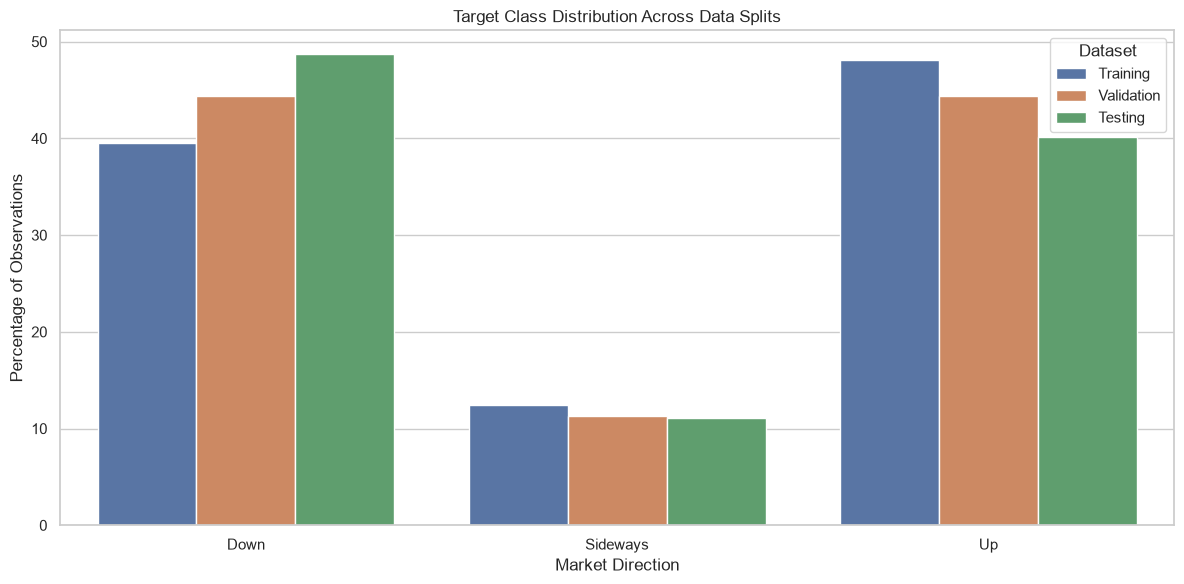

In [64]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Percentage",
    hue="Dataset"
)

plt.title("Target Class Distribution Across Data Splits")
plt.xlabel("Market Direction")
plt.ylabel("Percentage of Observations")

plt.tight_layout()
plt.show()

In [65]:
split_missing_summary = pd.DataFrame({
    "Training_Missing_%": X_train.isna().mean() * 100,
    "Validation_Missing_%": X_validation.isna().mean() * 100,
    "Testing_Missing_%": X_test.isna().mean() * 100
})

display(
    split_missing_summary.sort_values(
        "Training_Missing_%",
        ascending=False
    )
)

,Training_Missing_%,Validation_Missing_%,Testing_Missing_%
NIFTY_Return_Lag_10,33.4566,0.0000,0.0000
NIFTY_Return_Lag_1,32.3475,0.0000,0.0000
NIFTY_Return_Lag_2,31.9778,0.0000,0.0000
NIFTY_Return_Lag_3,30.1294,0.0000,0.0000
NIFTY_Return_Lag_5,29.3900,0.0000,0.0000
NIFTY_Momentum_10D,19.7782,0.0000,0.0000
NIFTY_Momentum_3D,19.5933,0.0000,0.0000
NIFTY_Return,19.4085,0.0000,0.0000
NIFTY_Momentum_5D,16.6359,0.0000,0.0000
CE_Relative_Volume_20D,2.2181,0.0000,0.0000


In [66]:
# Confirm no selected feature is entirely missing in the training period.
all_missing_training_features = X_train.columns[X_train.isna().all()].tolist()
assert not all_missing_training_features, (
    f"Unexpected all-missing training features: {all_missing_training_features}"
)

print("All selected features have at least one observed training value.")
print("Final model features:", len(feature_columns))
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Testing:", X_test.shape)


All selected features have at least one observed training value.
Final model features: 43
Training: (541, 43)
Validation: (115, 43)
Testing: (117, 43)


In [67]:
print("FINAL CHRONOLOGICAL SPLIT VALIDATION")
print("=" * 60)

print("\nTraining period:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

print("\nValidation period:")
print(validation_data["Date"].min(), "to", validation_data["Date"].max())

print("\nTesting period:")
print(test_data["Date"].min(), "to", test_data["Date"].max())

print("\nObservation counts:")
print("Training:", len(X_train))
print("Validation:", len(X_validation))
print("Testing:", len(X_test))

print("\nFeature counts:")
print("Training:", X_train.shape[1])
print("Validation:", X_validation.shape[1])
print("Testing:", X_test.shape[1])

# Verify feature alignment
assert list(X_train.columns) == list(X_validation.columns)
assert list(X_train.columns) == list(X_test.columns)

# Verify chronological order
assert train_data["Date"].max() < validation_data["Date"].min()
assert validation_data["Date"].max() < test_data["Date"].min()

# Verify no target leakage
assert not any(
    col in feature_columns
    for col in [
        "Date",
        "Target_Date",
        "Next_Session_Return",
        "Target_Direction",
        "Target_Label"
    ]
)

# Verify target classes
assert set(y_train.unique()).issubset({-1, 0, 1})
assert set(y_validation.unique()).issubset({-1, 0, 1})
assert set(y_test.unique()).issubset({-1, 0, 1})

print("\nAll final split validations passed.")

FINAL CHRONOLOGICAL SPLIT VALIDATION

Training period:
2021-01-01 00:00:00 to 2025-10-14 00:00:00

Validation period:
2025-10-16 00:00:00 to 2026-04-06 00:00:00

Testing period:
2026-04-08 00:00:00 to 2026-09-24 00:00:00

Observation counts:
Training: 541
Validation: 115
Testing: 117

Feature counts:
Training: 43
Validation: 43
Testing: 43

All final split validations passed.


## 10. Final Dataset Validation and Export

The final section prepares the engineered dataset for machine learning.

The following outputs will be generated:

1. Complete engineered market dataset.
2. Training dataset.
3. Validation dataset.
4. Testing dataset.
5. Target and feature metadata.
6. Dataset validation summary.

The datasets will be exported in Parquet format.

The training, validation, and testing datasets will retain their
chronological ordering.

Missing feature values will be preserved at this stage. Imputation
and scaling will be performed later using training data only,
within machine learning preprocessing pipelines.

The target variable and date information will be retained for
evaluation and traceability but will not be included as model
predictors.

In [68]:
# Create output directory
ML_DATA_DIR = PROJECT_ROOT / "data" / "ml"

ML_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("ML output directory:", ML_DATA_DIR)

ML output directory: /Users/yashraj/Projects/nifty50-FnO-eda/data/ml


In [69]:
# Assemble split datasets using the same final training-selected feature list.
def prepare_export_dataset(split_data, split_features, split_target):
    export_df = pd.concat(
        [
            split_data[["Date", "Target_Date"]].reset_index(drop=True),
            split_features.reset_index(drop=True),
            split_target.rename("Target_Direction").reset_index(drop=True)
        ],
        axis=1
    )
    assert len(export_df) == len(split_data) == len(split_features) == len(split_target)
    return export_df

full_ml_export = ml_dataset[
    ["Date", "Target_Date"] + feature_columns + ["Target_Direction"]
].copy()

train_export = prepare_export_dataset(train_data, X_train, y_train)
validation_export = prepare_export_dataset(validation_data, X_validation, y_validation)
test_export = prepare_export_dataset(test_data, X_test, y_test)

print("Export datasets prepared using the same final feature list.")
print("Full dataset:", full_ml_export.shape)
print("Training:", train_export.shape)
print("Validation:", validation_export.shape)
print("Testing:", test_export.shape)

assert list(train_export.columns) == list(validation_export.columns) == list(test_export.columns)
assert list(full_ml_export.columns) == list(train_export.columns)


Export datasets prepared using the same final feature list.
Full dataset: (775, 46)
Training: (541, 46)
Validation: (115, 46)
Testing: (117, 46)


In [70]:
# Export datasets
full_ml_export.to_parquet(
    ML_DATA_DIR / "full_ml_dataset.parquet",
    index=False
)

train_export.to_parquet(
    ML_DATA_DIR / "train_dataset.parquet",
    index=False
)

validation_export.to_parquet(
    ML_DATA_DIR / "validation_dataset.parquet",
    index=False
)

test_export.to_parquet(
    ML_DATA_DIR / "test_dataset.parquet",
    index=False
)

# Save target audit data separately.
# Next_Session_Return is for evaluation and auditing only,
# never a predictor.
target_audit = market_daily[
    [
        "Date",
        "Target_Date",
        "Next_Session_Return",
        "Target_Direction",
        "Target_Label"
    ]
].copy()

target_audit.to_parquet(
    ML_DATA_DIR / "target_audit.parquet",
    index=False
)

print("All Parquet datasets exported successfully.")

All Parquet datasets exported successfully.


In [71]:
import json

feature_metadata = {
    "feature_columns": feature_columns,
    "number_of_features": len(feature_columns),
    "feature_selection_fit_on": "training partition only",
    "maximum_training_missing_percentage": MAX_MISSING_PERCENTAGE,
    "removed_high_missing_features": features_over_missing_limit,
    "removed_training_constant_features": constant_features_train
}

with open(ML_DATA_DIR / "feature_columns.json", "w") as file:
    json.dump(feature_metadata, file, indent=4)

metadata = {
    "project": "NIFTY 50 Futures and Options ML",
    "notebook": "05_feature_engineering",
    "prediction_objective": "Next-observation direction classification using derivatives-implied underlying proxy",
    "target_column": "Target_Direction",
    "target_mapping": {"-1": "Down", "0": "Sideways", "1": "Up"},
    "sideways_threshold_percent": SIDEWAYS_THRESHOLD,
    "feature_count": len(feature_columns),
    "feature_selection_fit_on": "training partition only",
    "split_ratios": {"training": TRAIN_RATIO, "validation": VALIDATION_RATIO, "testing": TEST_RATIO},
    "training_start": str(train_data["Date"].min().date()),
    "training_end": str(train_data["Date"].max().date()),
    "validation_start": str(validation_data["Date"].min().date()),
    "validation_end": str(validation_data["Date"].max().date()),
    "testing_start": str(test_data["Date"].min().date()),
    "testing_end": str(test_data["Date"].max().date()),
    "underlying_source": "Daily median Underlying Value from supplied NIFTY futures contracts; CE then PE fallback where prior source is missing",
    "underlying_source_limitation": "Derivatives-implied proxy, not an independent official NIFTY 50 spot close series; missing observations are not imputed",
    "underlying_proxy_coverage_percent": round(market_daily["Underlying_Value"].notna().mean() * 100, 2),
    "valid_target_observations": int(market_daily["Target_Direction"].notna().sum()),
    "total_market_dates": int(len(market_daily))
}

with open(ML_DATA_DIR / "ml_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Feature list and modelling metadata saved with proxy limitations documented.")


Feature list and modelling metadata saved with proxy limitations documented.


In [72]:
# Reload exported datasets.
reloaded_full = pd.read_parquet(ML_DATA_DIR / "full_ml_dataset.parquet")
reloaded_train = pd.read_parquet(ML_DATA_DIR / "train_dataset.parquet")
reloaded_validation = pd.read_parquet(ML_DATA_DIR / "validation_dataset.parquet")
reloaded_test = pd.read_parquet(ML_DATA_DIR / "test_dataset.parquet")

expected_exports = [
    (reloaded_full, full_ml_export),
    (reloaded_train, train_export),
    (reloaded_validation, validation_export),
    (reloaded_test, test_export)
]

for reloaded, expected in expected_exports:
    assert len(reloaded) == len(expected)
    assert list(reloaded.columns) == list(expected.columns)
    assert reloaded["Date"].notna().all()
    assert reloaded["Date"].is_monotonic_increasing
    assert reloaded["Date"].is_unique
    assert reloaded["Target_Direction"].notna().all()
    assert set(reloaded["Target_Direction"].unique()).issubset({-1, 0, 1})

assert list(X_train.columns) == list(X_validation.columns) == list(X_test.columns)
assert list(X_train.columns) == feature_columns
assert reloaded_train["Date"].max() < reloaded_validation["Date"].min()
assert reloaded_validation["Date"].max() < reloaded_test["Date"].min()
assert reloaded_train["Target_Date"].max() < reloaded_validation["Date"].min()
assert reloaded_validation["Target_Date"].max() < reloaded_test["Date"].min()

print("All exported datasets reloaded and passed row, schema, date, target, and split-boundary checks.")


All exported datasets reloaded and passed row, schema, date, target, and split-boundary checks.


In [73]:
final_dataset_summary = pd.DataFrame({
    "Dataset": ["Full ML Dataset", "Training Dataset", "Validation Dataset", "Testing Dataset"],
    "Observations": [len(full_ml_export), len(train_export), len(validation_export), len(test_export)],
    "Features": [len(feature_columns)] * 4,
    "Start Date": [full_ml_export["Date"].min(), train_export["Date"].min(), validation_export["Date"].min(), test_export["Date"].min()],
    "End Date": [full_ml_export["Date"].max(), train_export["Date"].max(), validation_export["Date"].max(), test_export["Date"].max()]
})

display(final_dataset_summary)


,Dataset,Observations,Features,Start Date,End Date
0,Full ML Dataset,775,43,2021-01-01,2026-09-24
1,Training Dataset,541,43,2021-01-01,2025-10-14
2,Validation Dataset,115,43,2025-10-16,2026-04-06
3,Testing Dataset,117,43,2026-04-08,2026-09-24


In [74]:
print("=" * 70)
print("NOTEBOOK 5 — FINAL VALIDATION REPORT")
print("=" * 70)

print("\n1. DATA AND TARGET PROVENANCE")
print("Underlying proxy source: supplied derivatives Underlying Value fields")
print("Proxy coverage (%):", round(market_daily["Underlying_Value"].notna().mean() * 100, 2))
print("Valid next-session targets:", int(market_daily["Target_Direction"].notna().sum()))
print("Total common trading dates:", len(market_daily))
print("Target coverage (%):", round(market_daily["Target_Direction"].notna().mean() * 100, 2))
print("Limitation: this is a derivatives-implied proxy, not an independent spot-index close series.")

print("\n2. FINAL DATASET INFORMATION")
print("Full labelled observations:", len(full_ml_export))
print("Final model features:", len(feature_columns))

print("\n3. CHRONOLOGICAL SPLIT INFORMATION")
for name, df in [("Training", train_export), ("Validation", validation_export), ("Testing", test_export)]:
    print(f"{name}: {len(df)} observations | {df['Date'].min().date()} to {df['Date'].max().date()}")

print("\n4. TARGET DISTRIBUTION")
for name, df in [("Training", train_export), ("Validation", validation_export), ("Testing", test_export)]:
    print(f"\n{name}:")
    display(df["Target_Direction"].value_counts(normalize=True).reindex([-1, 0, 1], fill_value=0).mul(100).rename("Percentage").to_frame())

print("\n5. MISSING VALUES IN PREDICTOR FEATURES")
for name, df in [("Full", full_ml_export), ("Training", train_export), ("Validation", validation_export), ("Testing", test_export)]:
    print(f"{name}: {int(df[feature_columns].isna().sum().sum())} missing feature values")

print("\n6. OUTPUT FILES")
for path in sorted(ML_DATA_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name}: {path.stat().st_size / 1024:.2f} KB")

print("\nNotebook 5 export validation completed.")


NOTEBOOK 5 — FINAL VALIDATION REPORT

1. DATA AND TARGET PROVENANCE
Underlying proxy source: supplied derivatives Underlying Value fields
Proxy coverage (%): 68.26
Valid next-session targets: 775
Total common trading dates: 1421
Target coverage (%): 54.54
Limitation: this is a derivatives-implied proxy, not an independent spot-index close series.

2. FINAL DATASET INFORMATION
Full labelled observations: 775
Final model features: 43

3. CHRONOLOGICAL SPLIT INFORMATION
Training: 541 observations | 2021-01-01 to 2025-10-14
Validation: 115 observations | 2025-10-16 to 2026-04-06
Testing: 117 observations | 2026-04-08 to 2026-09-24

4. TARGET DISTRIBUTION

Training:


,Percentage
Target_Direction,
-1,39.5564
0,12.3845
1,48.0591



Validation:


,Percentage
Target_Direction,
-1,44.3478
0,11.3043
1,44.3478



Testing:


,Percentage
Target_Direction,
-1,48.7179
0,11.1111
1,40.1709



5. MISSING VALUES IN PREDICTOR FEATURES
Full: 1422 missing feature values
Training: 1422 missing feature values
Validation: 0 missing feature values
Testing: 0 missing feature values

6. OUTPUT FILES
feature_columns.json: 1.83 KB
full_ml_dataset.parquet: 311.62 KB
ml_metadata.json: 1.18 KB
target_audit.parquet: 34.87 KB
test_dataset.parquet: 72.55 KB
train_dataset.parquet: 222.73 KB
validation_dataset.parquet: 71.89 KB

Notebook 5 export validation completed.


# 11. Conclusion

This notebook transforms the supplied NIFTY 50 Futures, Call Options (CE),
and Put Options (PE) datasets into a structured machine-learning dataset.

The engineered predictors include:

- Historical returns, lags, momentum, and moving-average deviations.
- Rolling volatility and trading-activity indicators.
- Futures, CE, and PE volume and open-interest features.
- Put-Call Ratio and options activity indicators.

The three-class target represents the next observed trading-date direction:
Up (1), Down (-1), or Sideways (0), using a threshold of ±0.10%.

The data is split chronologically. Boundary observations are purged so that
next-session target dates do not cross from one partition into the next.
Feature missingness and constant-feature filters are learned from the training
partition only. Missing values remain in the exported datasets; imputation and
scaling should be fitted inside training-only machine-learning pipelines in Notebook 6.

The resulting Parquet datasets and JSON metadata are prepared for model
training and evaluation in Notebook 6.
